# SMS Spam Message Detection Using Machine Learning
### A Comparative Study of Naive Bayes, Logistic Regression and Support Vector Machine with Bag-of-Words and TF-IDF Features

**Machine Learning Case Study 8** — Department of Artificial Intelligence and Machine Learning, BMS Institute of Technology and Management, Bengaluru

**Team:** Javeria Taj · Shaik Mohammed Mustaqeem Rafi · Mohammed Mohsin · Varun Kalmane

**Problem statement.** Classify SMS messages as Spam or Ham. Apply text preprocessing such as lowercasing, tokenization and stop-word removal, represent messages using Bag of Words and TF-IDF, and compare classifiers.
Dataset: UCI SMS Spam Collection — https://archive.ics.uci.edu/dataset/228/sms+spam+collection.
Suggested ML techniques: Naive Bayes, Logistic Regression, SVM, TF-IDF.

The system takes the raw text of one SMS message as input and classifies it as **Spam (1)** or **Ham (0)**.

This notebook is a walkthrough. All logic lives in the `src/` package; the notebook only calls it and shows the outputs. Sections follow report Chapters 3–6.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

from src import config as C
from src.data import build_clean_dataset, save_split_table, get_split
from src.preprocess import clean_text, _self_check
from src.eda import run_eda
from src.train import worked_example, train_all
from src.evaluate import run_evaluation
from src.interpret import run_interpretation
from src.flowchart import draw_workflow
from src.ablation import run_ablation
from src.predict import predict

def fig(name, width=720):
    display(Image(filename=str(C.FIG_DIR / name), width=width))

def table(name):
    return pd.read_csv(C.TABLE_DIR / name, keep_default_na=False)

print("Random state:", C.RANDOM_STATE, "| test size:", C.TEST_SIZE, "| CV folds:", C.CV_FOLDS)

Random state: 42 | test size: 0.2 | CV folds: 5


## 1. Dataset loading and cleaning (Report §3.1, §4.1)
The raw file is tab-separated (`label<TAB>message`) and is read with `quoting=3` (no quote handling) because messages contain quote characters. Labels are mapped to ham = 0, spam = 1; HTML entities are unescaped; exact duplicate messages are removed **before** the train/test split so that no message appears in both sets.

In [2]:
df, log = build_clean_dataset()
print(json.dumps(log, indent=2))
df.head()

Loaded raw file: 5574 rows
Duplicates removed: 414 {'ham': 309, 'spam': 105}
Clean rows: 5160 {'ham': 4518, 'spam': 642}
{
  "n_raw": 5574,
  "raw_class_counts": {
    "ham": 4827,
    "spam": 747
  },
  "missing_values": 0,
  "n_html_entity_messages": 309,
  "n_duplicates_removed": 414,
  "duplicates_by_class": {
    "ham": 309,
    "spam": 105
  },
  "n_texts_with_conflicting_labels": 0,
  "n_clean": 5160,
  "clean_class_counts": {
    "ham": 4518,
    "spam": 642
  }
}


,label,target,text,text_clean,n_chars,n_words,n_digits,n_upper,has_url,has_currency
0,ham,0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci...",go until jurong point crazy available only in bugis n great world la e buffet cine the...,111,20,0,3,0,0
1,ham,0,Ok lar... Joking wif u oni...,ok lar joking wif u oni,29,6,0,2,0,0
2,spam,1,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,free entry in numtoken a wkly comp to win fa cup final tkts numtoken st may numtoken t...,155,28,25,10,0,0
3,ham,0,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,49,11,0,2,0,0
4,ham,0,"Nah I don't think he goes to usf, he lives around here though",nah i don t think he goes to usf he lives around here though,61,13,0,2,0,0


In [3]:
display(table("table_3_5_duplicates.csv"))
display(df.dtypes.to_frame("dtype").T)

,Class,Before,Duplicates removed,After,Percent removed
0,ham,4827,309,4518,6.40
1,spam,747,105,642,14.06
2,total,5574,414,5160,7.43


,label,target,text,text_clean,n_chars,n_words,n_digits,n_upper,has_url,has_currency
dtype,str,int64,str,str,int64,int64,int64,int64,int64,int64


## 2. Exploratory data analysis (Report Chapter 3)

In [4]:
obs = run_eda()
display(table("table_3_1_overview.csv"))
display(table("table_3_4_summary_stats.csv"))

Loaded raw file: 5574 rows
Figures:
  saved outputs/figures/fig_3_1_class_distribution.png


  saved outputs/figures/fig_3_2_length_chars.png


  saved outputs/figures/fig_3_3_length_words.png
  saved outputs/figures/fig_3_4_digits_by_class.png


  saved outputs/figures/fig_3_5_top_words_ham.png
  saved outputs/figures/fig_3_6_top_words_spam.png


  saved outputs/figures/fig_3_7_wordclouds.png
  saved outputs/figures/fig_3_8_feature_correlation.png
EDA done: {'n_raw': 5574, 'n_clean': 5160, 'spam_pct': 12.44, 'n_duplicates_removed': 414, 'vocab_size_eda': 7440}


,Attribute,Value
0,Dataset name,SMS Spam Collection
1,Source,UCI Machine Learning Repository
2,URL,https://archive.ics.uci.edu/dataset/228/sms+spam+collection
3,Records (raw),"5,574"
4,Records (after removing duplicates),"5,160"
5,Class counts (raw),"ham 4,827; spam 747"
6,Class counts (after removing duplicates),"ham 4,518; spam 642"
7,Features,1 text input (message) + 1 target
8,Target variable,"label (ham / spam), encoded ham = 0, spam = 1"
9,Task,Binary text classification


,Class,Feature,Mean,Median,Std,Min,Max
0,ham,Characters,70.43,52.0,55.95,2,910
1,ham,Words,14.23,11.0,11.16,1,171
2,ham,Digits,0.30,0.0,1.02,0,23
3,spam,Characters,137.41,148.0,29.98,13,223
4,spam,Words,23.70,25.0,5.97,2,35
5,spam,Digits,15.44,16.0,8.94,0,47


### 2.1 Class distribution (Fig. 3.1)
The data are imbalanced (about one spam message for every seven ham messages), so accuracy alone is misleading; F1 of the spam class and PR-AUC are used instead, and the split is stratified.

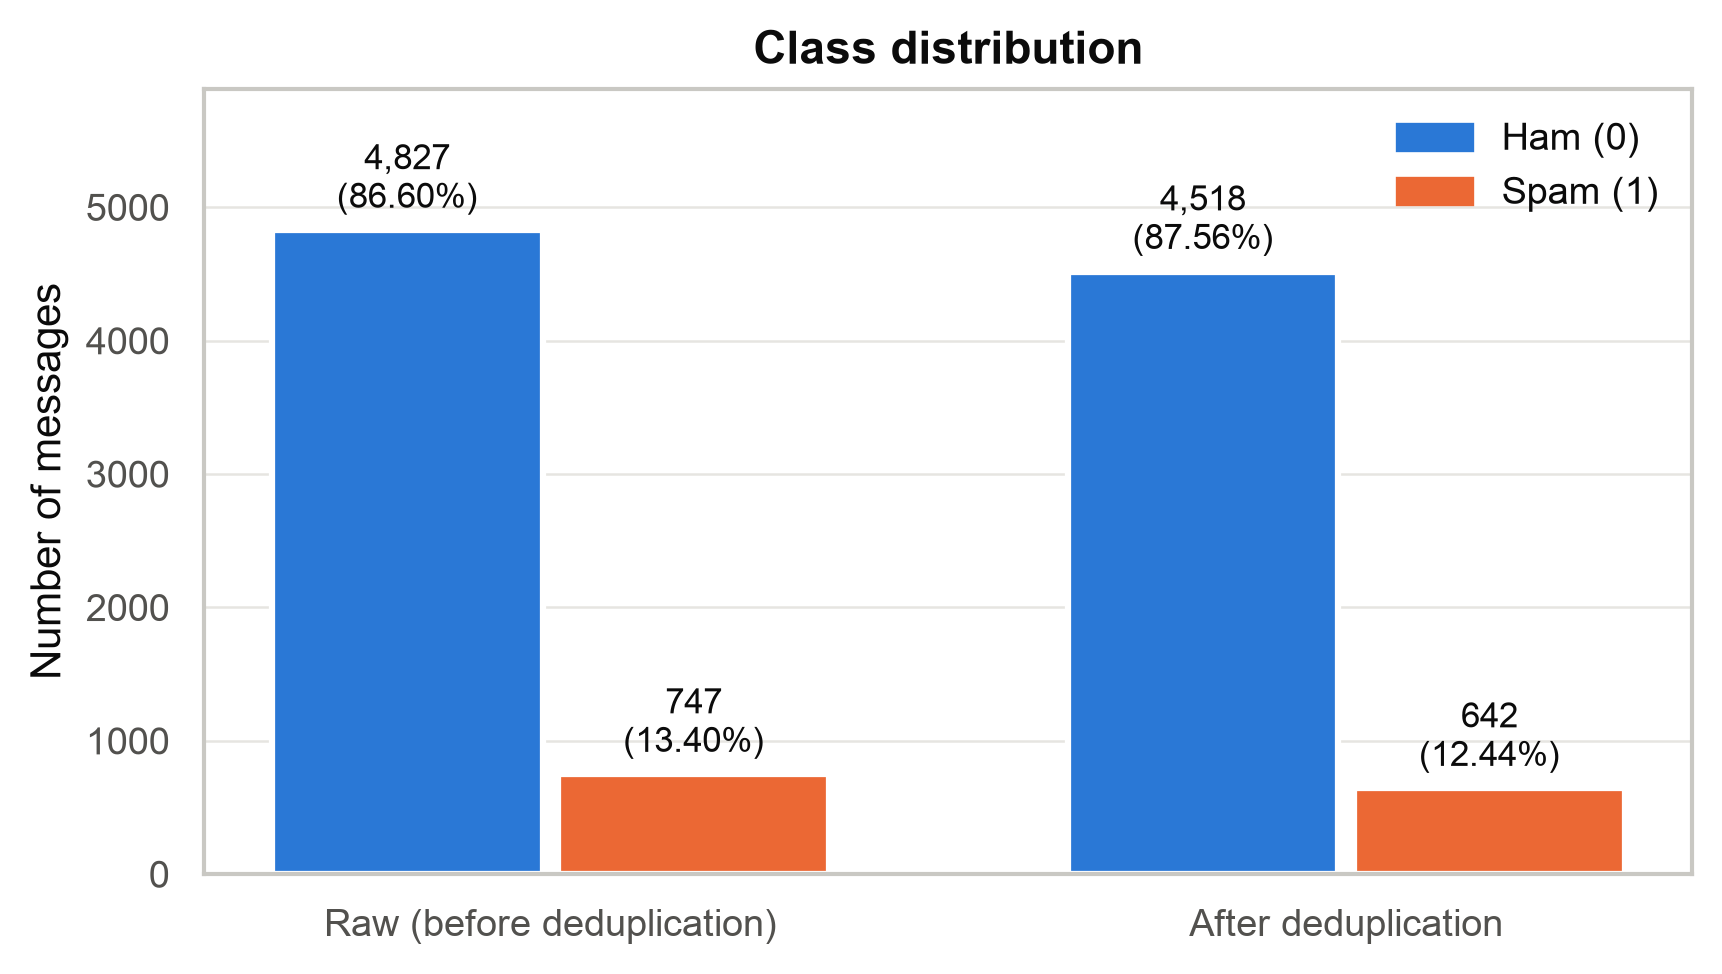

Spam share after deduplication: 12.44%  (ham 87.56%)


In [5]:
fig("fig_3_1_class_distribution.png")
print(f"Spam share after deduplication: {obs['spam_pct']}%  (ham {obs['ham_pct']}%)")

### 2.2 Message length (Figs. 3.2, 3.3)
Spam messages are much longer than ham and cluster just below the 160-character single-SMS limit.

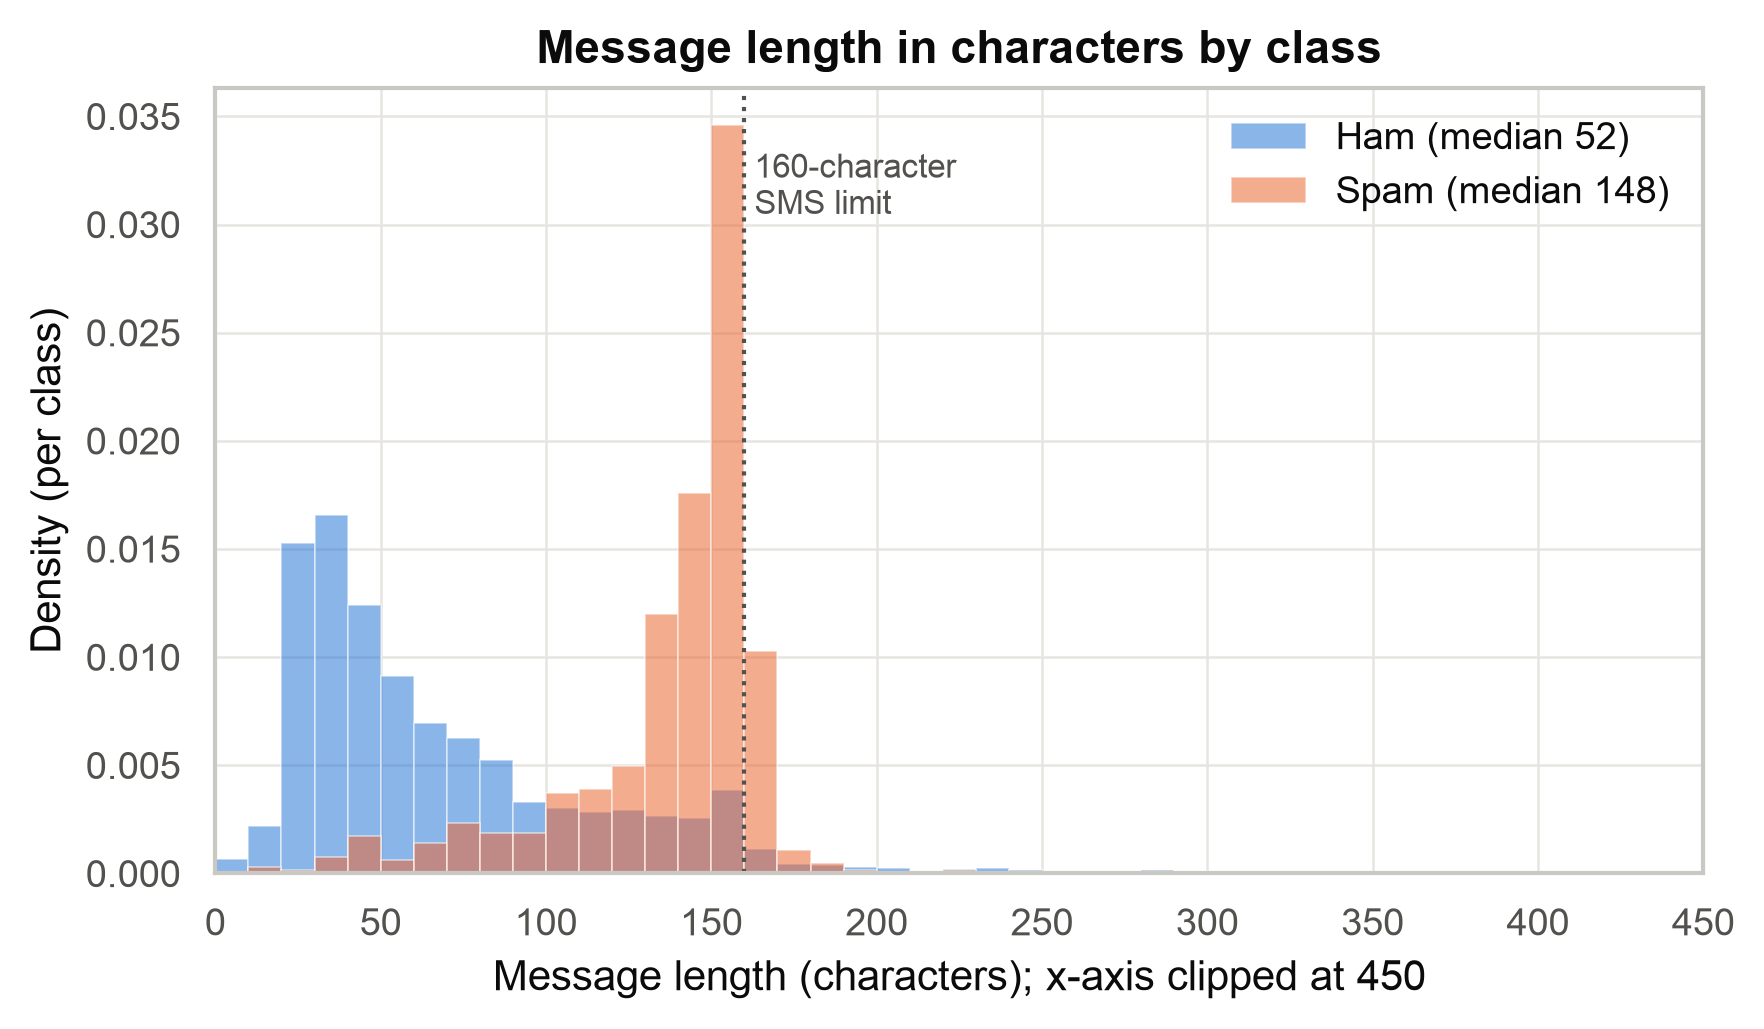

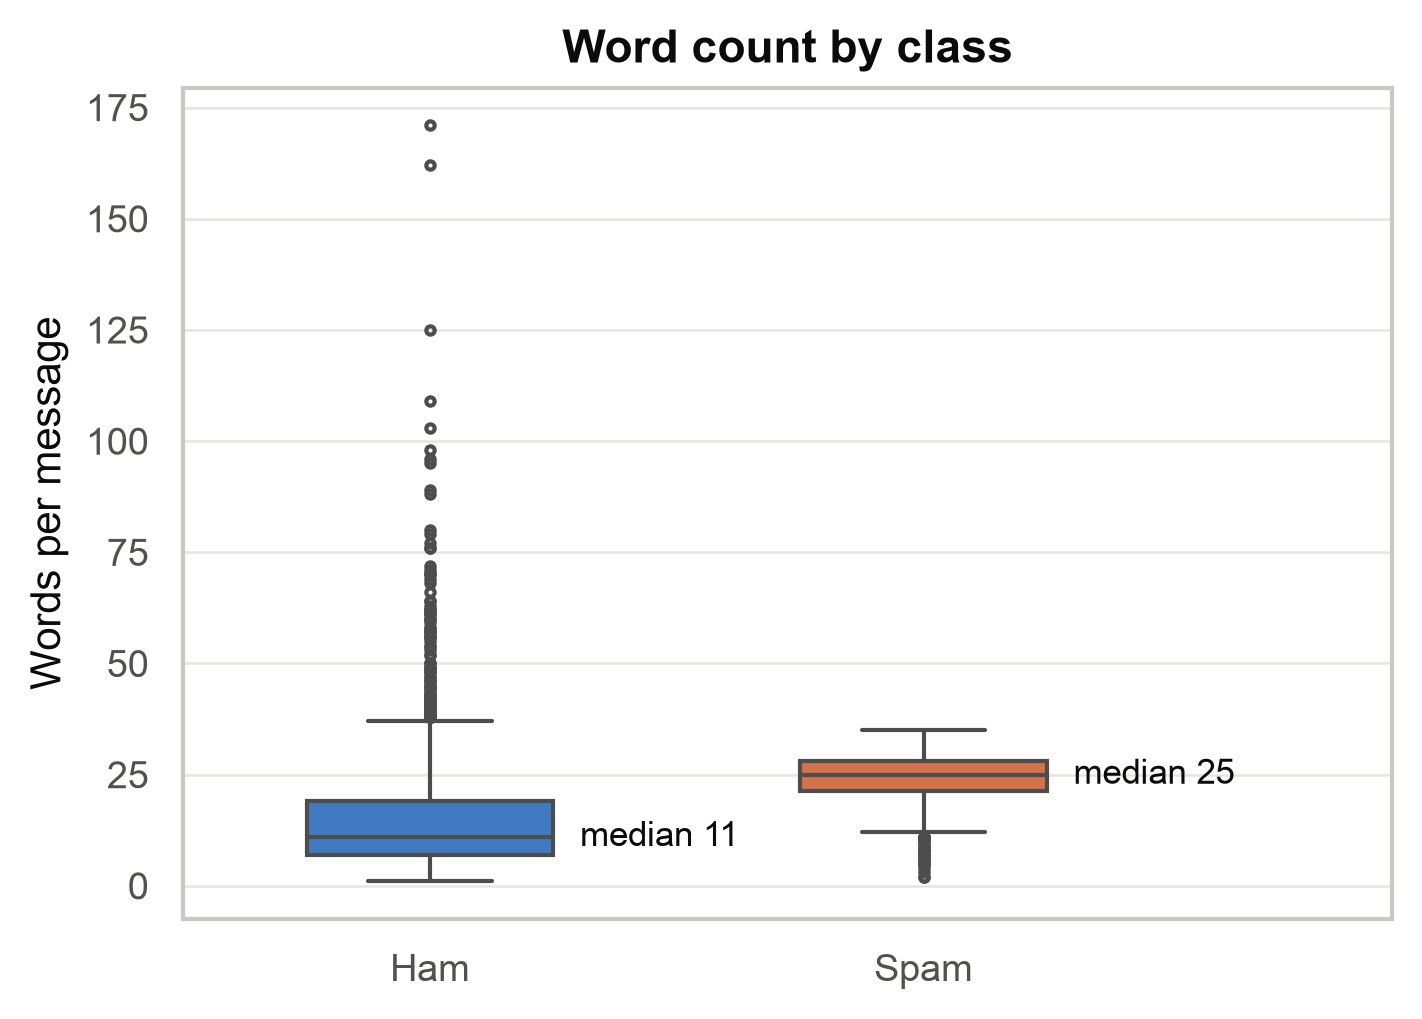

Median characters: {'ham': 52.0, 'spam': 148.0} | median words: {'ham': 11.0, 'spam': 25.0}


In [6]:
fig("fig_3_2_length_chars.png"); fig("fig_3_3_length_words.png", 560)
print("Median characters:", obs["median_chars"], "| median words:", obs["median_words"])

### 2.3 Digits, URLs and currency (Fig. 3.4)
Spam is digit-heavy (phone numbers, short codes, prices). This motivates replacing numbers, URLs and currency symbols with normalisation tokens.

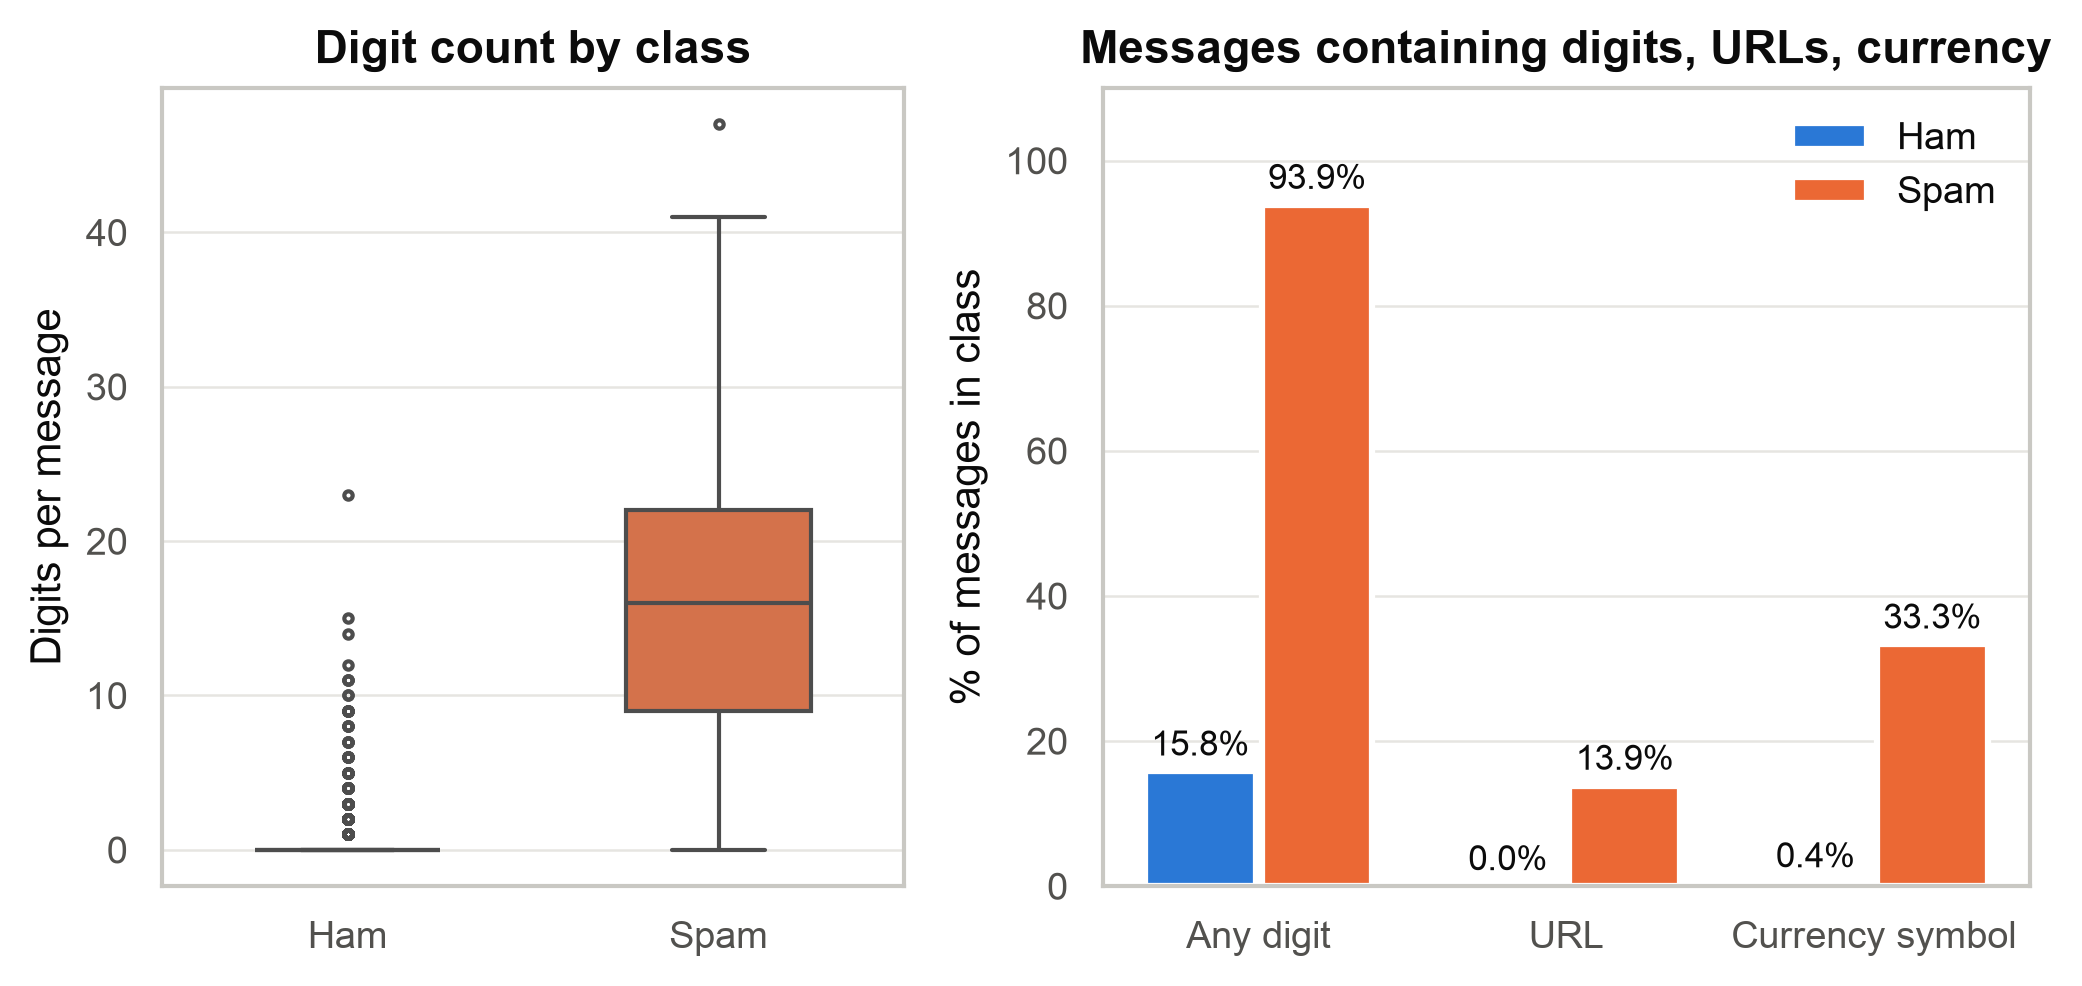

Messages with any digit (%): {'ham': 15.83, 'spam': 93.93} | with currency (%): {'ham': 0.42, 'spam': 33.33}


In [7]:
fig("fig_3_4_digits_by_class.png")
print("Messages with any digit (%):", obs["pct_with_digits"], "| with currency (%):", obs["pct_with_currency"])

### 2.4 Frequent tokens and word clouds (Figs. 3.5–3.7)

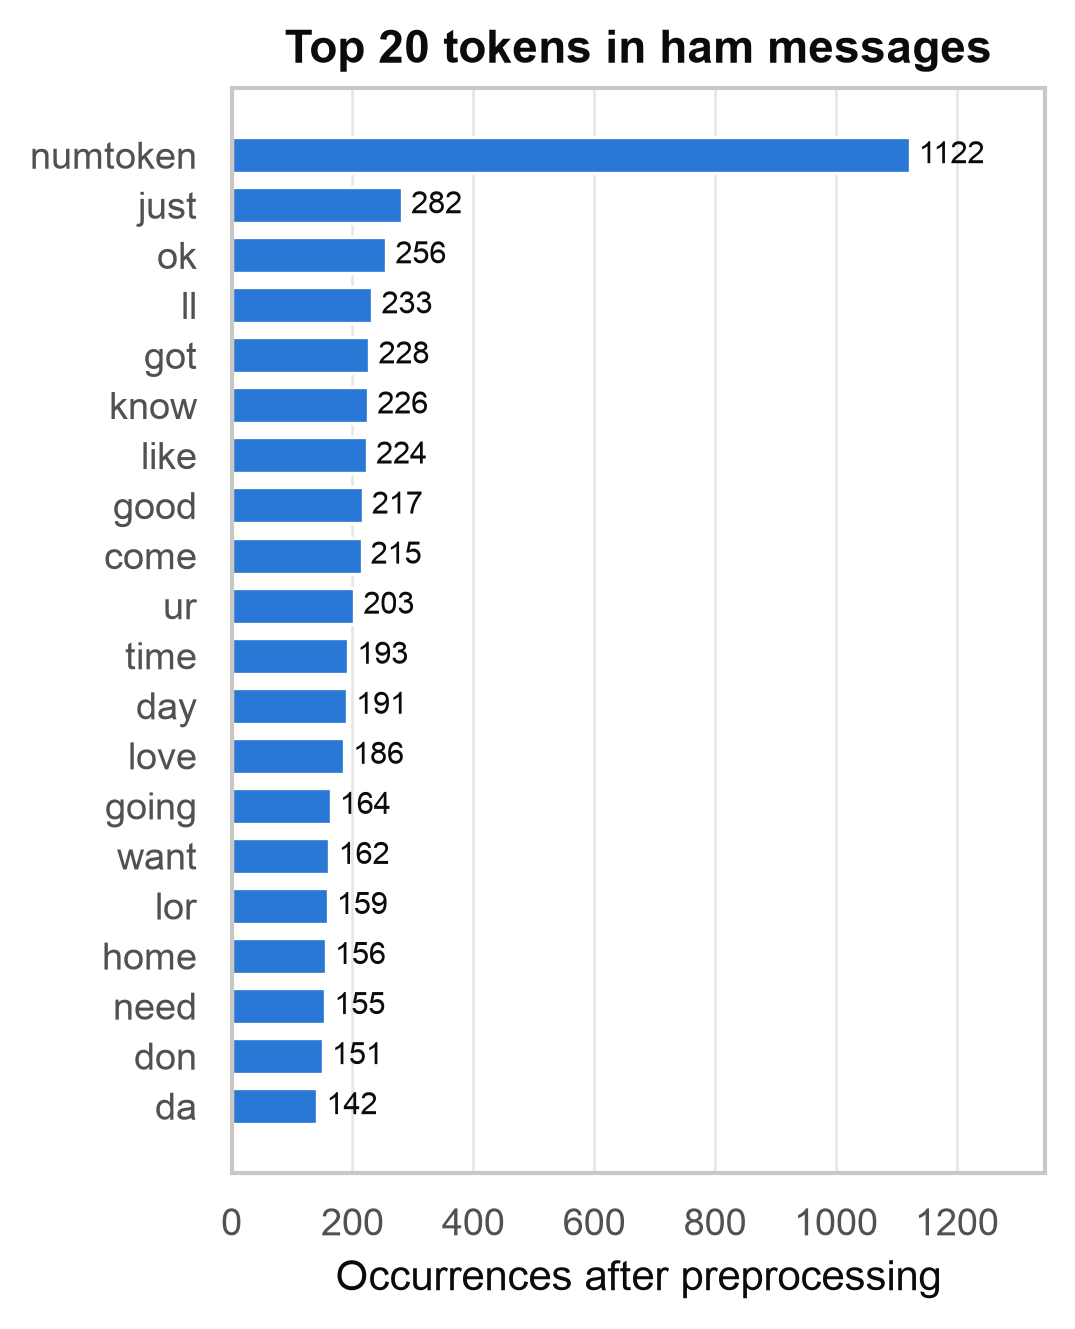

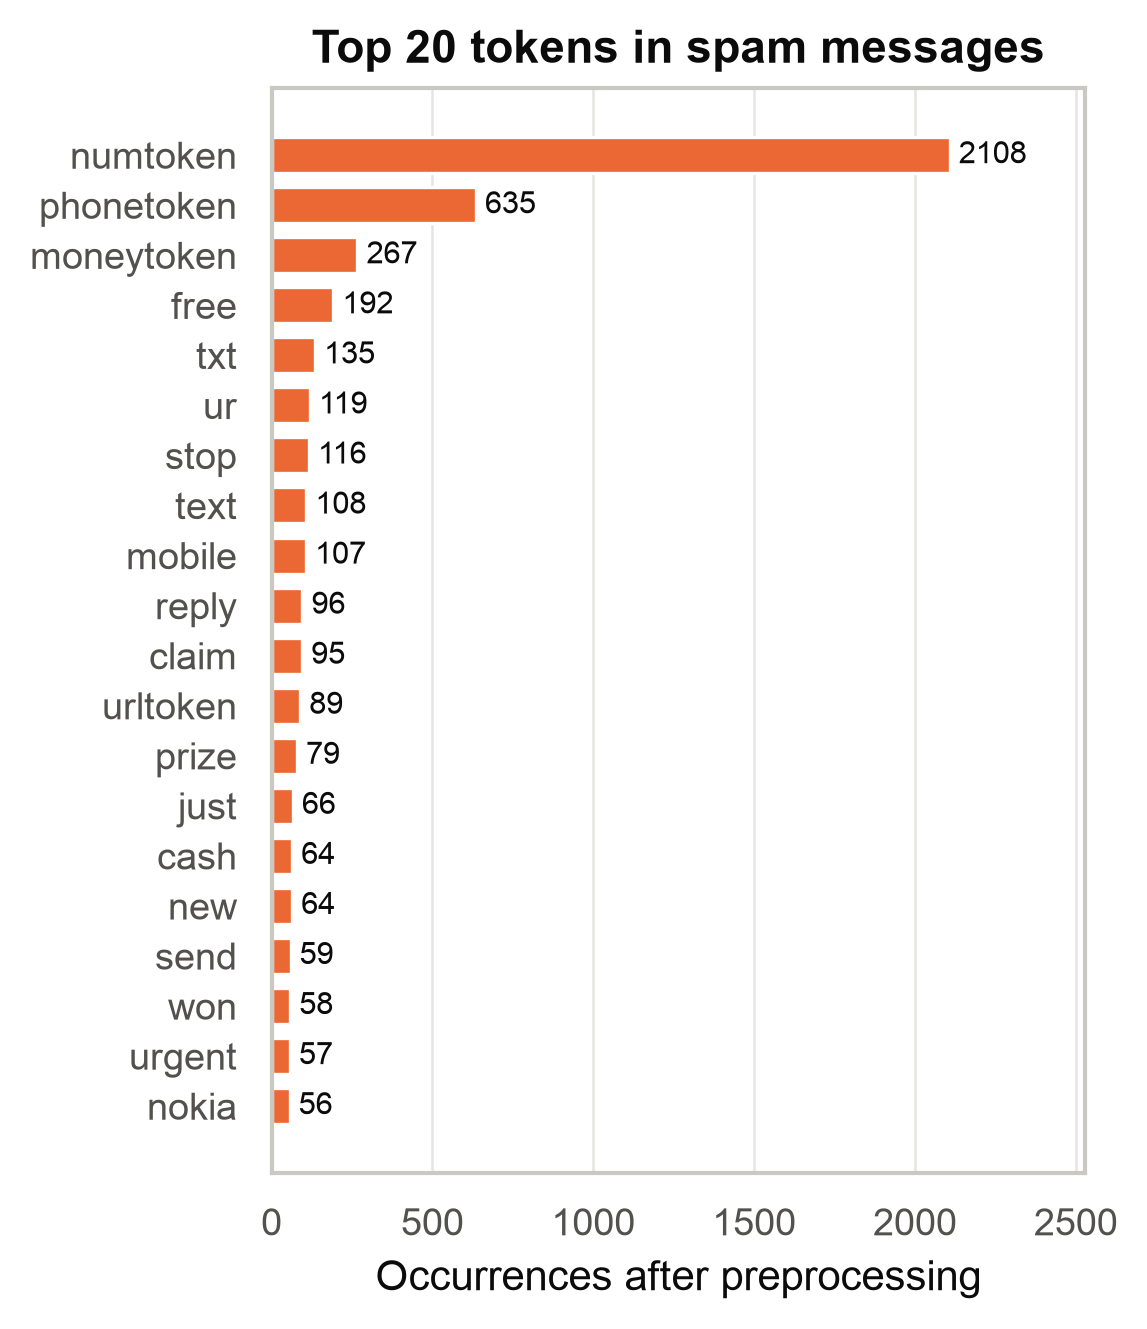

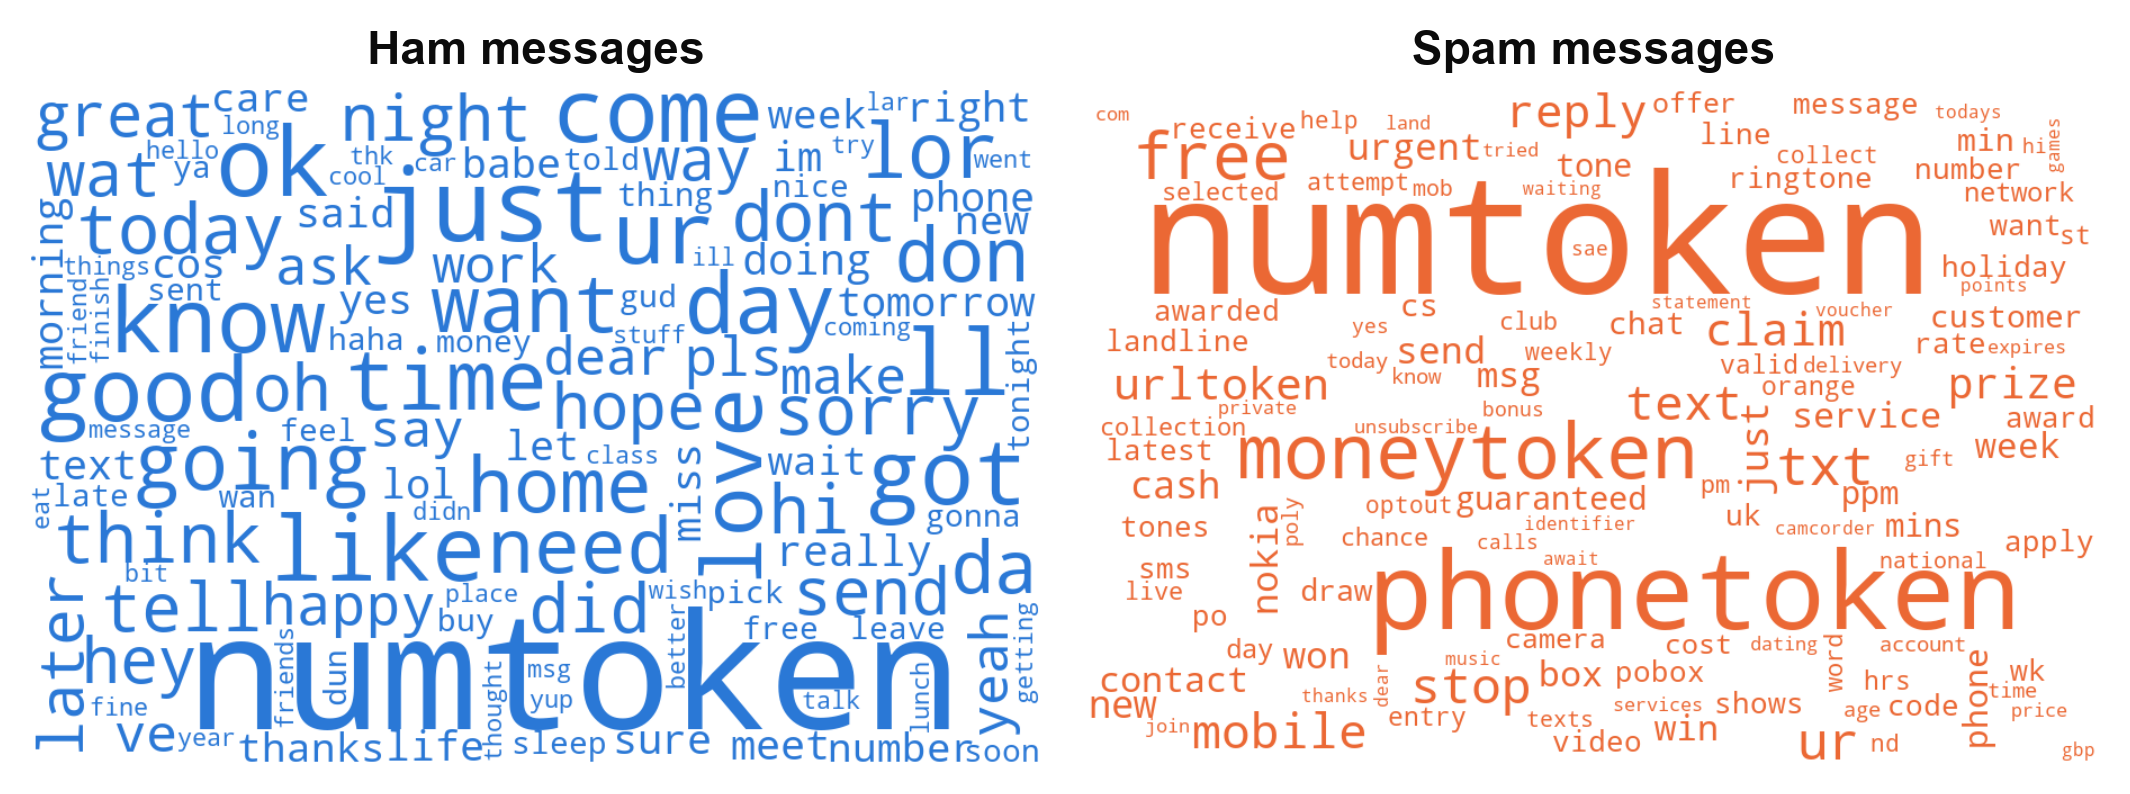

In [8]:
fig("fig_3_5_top_words_ham.png", 560); fig("fig_3_6_top_words_spam.png", 560); fig("fig_3_7_wordclouds.png")

### 2.5 Correlation of engineered numeric features (Fig. 3.8)
These numeric features are used for EDA only; the models use text features only.

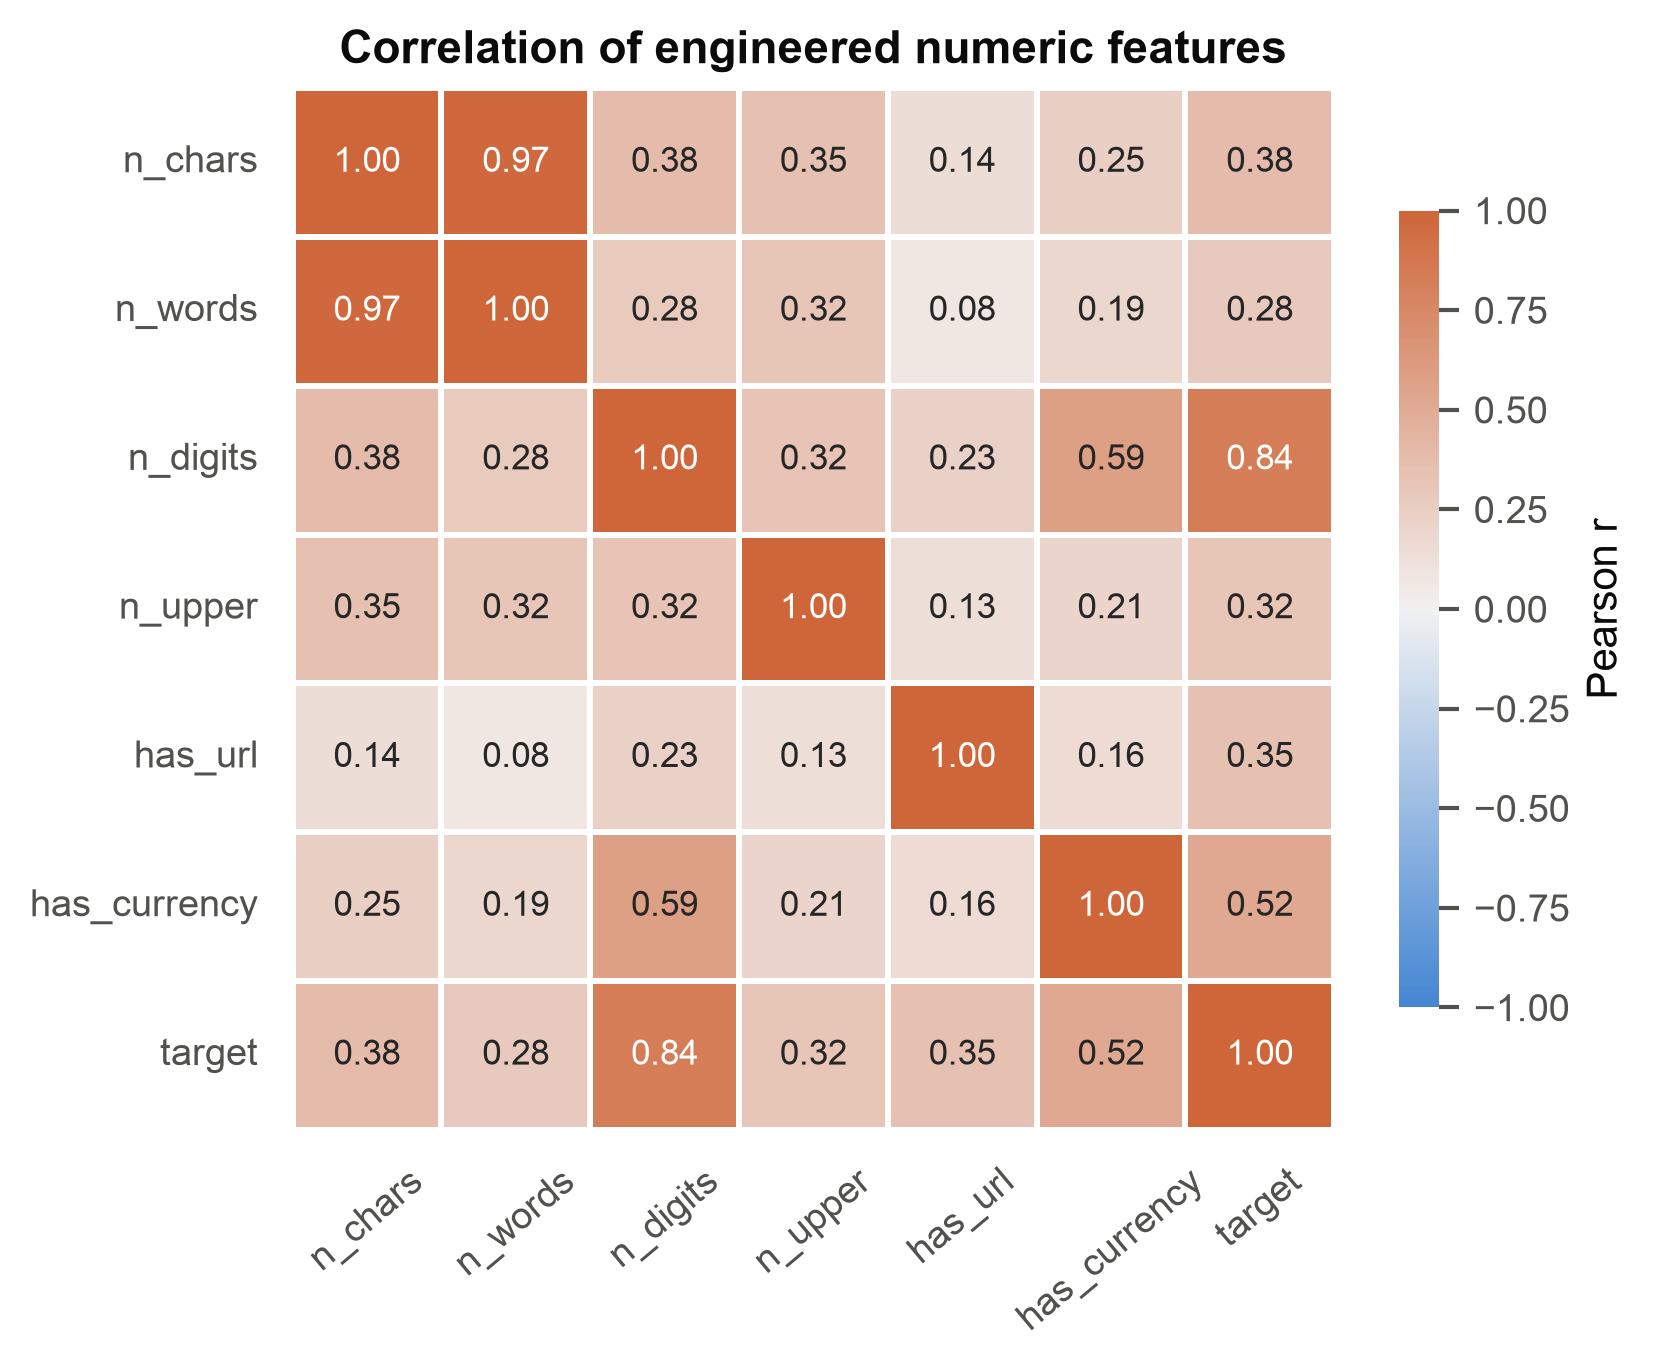

In [9]:
fig("fig_3_8_feature_correlation.png", 560)

## 3. Preprocessing and feature engineering (Report Chapter 4)
`clean_text` lowercases, replaces URLs, e-mail addresses, currency symbols and numbers with tokens, and keeps only letters. The vectorizer then tokenises (tokens of at least two letters) and removes scikit-learn's English stop words.

In [10]:
_self_check()
for t in df.sample(5, random_state=C.RANDOM_STATE).text:
    print(f"{t[:70]!r:75} -> {clean_text(t)[:60]!r}")

preprocess self-check: all assertions passed
  'WINNER!! Claim £1000 now: call 09061234567'       -> 'winner claim moneytoken numtoken now call phonetoken'
  'Visit http://bit.ly/abc or www.win.com'           -> 'visit urltoken or urltoken'
  'Mail me at John.Doe@example.com ok?'              -> 'mail me at emailtoken ok'
  'Meet at 5, room 12'                               -> 'meet at numtoken room numtoken'
  "I'm   gonna be HOME soon"                         -> 'i m gonna be home soon'
'they released another Italian one today and it has a cosign option'        -> 'they released another italian one today and it has a cosign '
"I'm not. She lip synced with shangela."                                    -> 'i m not she lip synced with shangela'
"Carlos'll be here in a minute if you still need to buy"                    -> 'carlos ll be here in a minute if you still need to buy'
'Ok ill tell the company'                                                   -> 'ok ill tell the company'
"That

### 3.1 Worked example: Bag of Words vs TF-IDF (Table 4.2)

In [11]:
msgs, bow, tfidf, idf = worked_example()
display(msgs); display(bow); display(pd.concat([tfidf, idf]))

,id,message,cleaned
0,m1,WIN a FREE prize! Call 09061234567,win a free prize call phonetoken
1,m2,Call me when you are free,call me when you are free
2,m3,Free entry to win a prize,free entry to win a prize


,entry,free,phonetoken,prize,win
m1,0,1,1,1,1
m2,0,1,0,0,0
m3,1,1,0,1,1


,entry,free,phonetoken,prize,win
m1,0.0000,0.3731,0.6317,0.4805,0.4805
m2,0.0000,1.0000,0.0000,0.0000,0.0000
m3,0.6317,0.3731,0.0000,0.4805,0.4805
idf,1.6931,1.0000,1.6931,1.2877,1.2877


### 3.2 Train/test split (Table 4.1)
Stratified 80/20 split with `random_state=42`. Validation uses 5-fold stratified cross-validation inside the training set. The vectorizer is a step of the `Pipeline`, so its vocabulary and IDF weights are learned from training folds only.

In [12]:
save_split_table()

,Subset,Records,Percent,Ham,Spam,Spam_percent,Note
0,Training,4128,80.00,3614,514,12.45,Used to fit the final model (vectorizer + classifier)
1,Validation,825-826 per fold,16.01,722-723,102-103,12.45,Validation: 5-fold CV within training set (each fold held out once)
2,Testing,1032,20.00,904,128,12.40,Held-out; used once for final evaluation
3,Total,5160,100.00,4518,642,12.44,After deduplication


## 4. Model development (Report Chapter 5)

  saved outputs/figures/fig_5_1_workflow.png


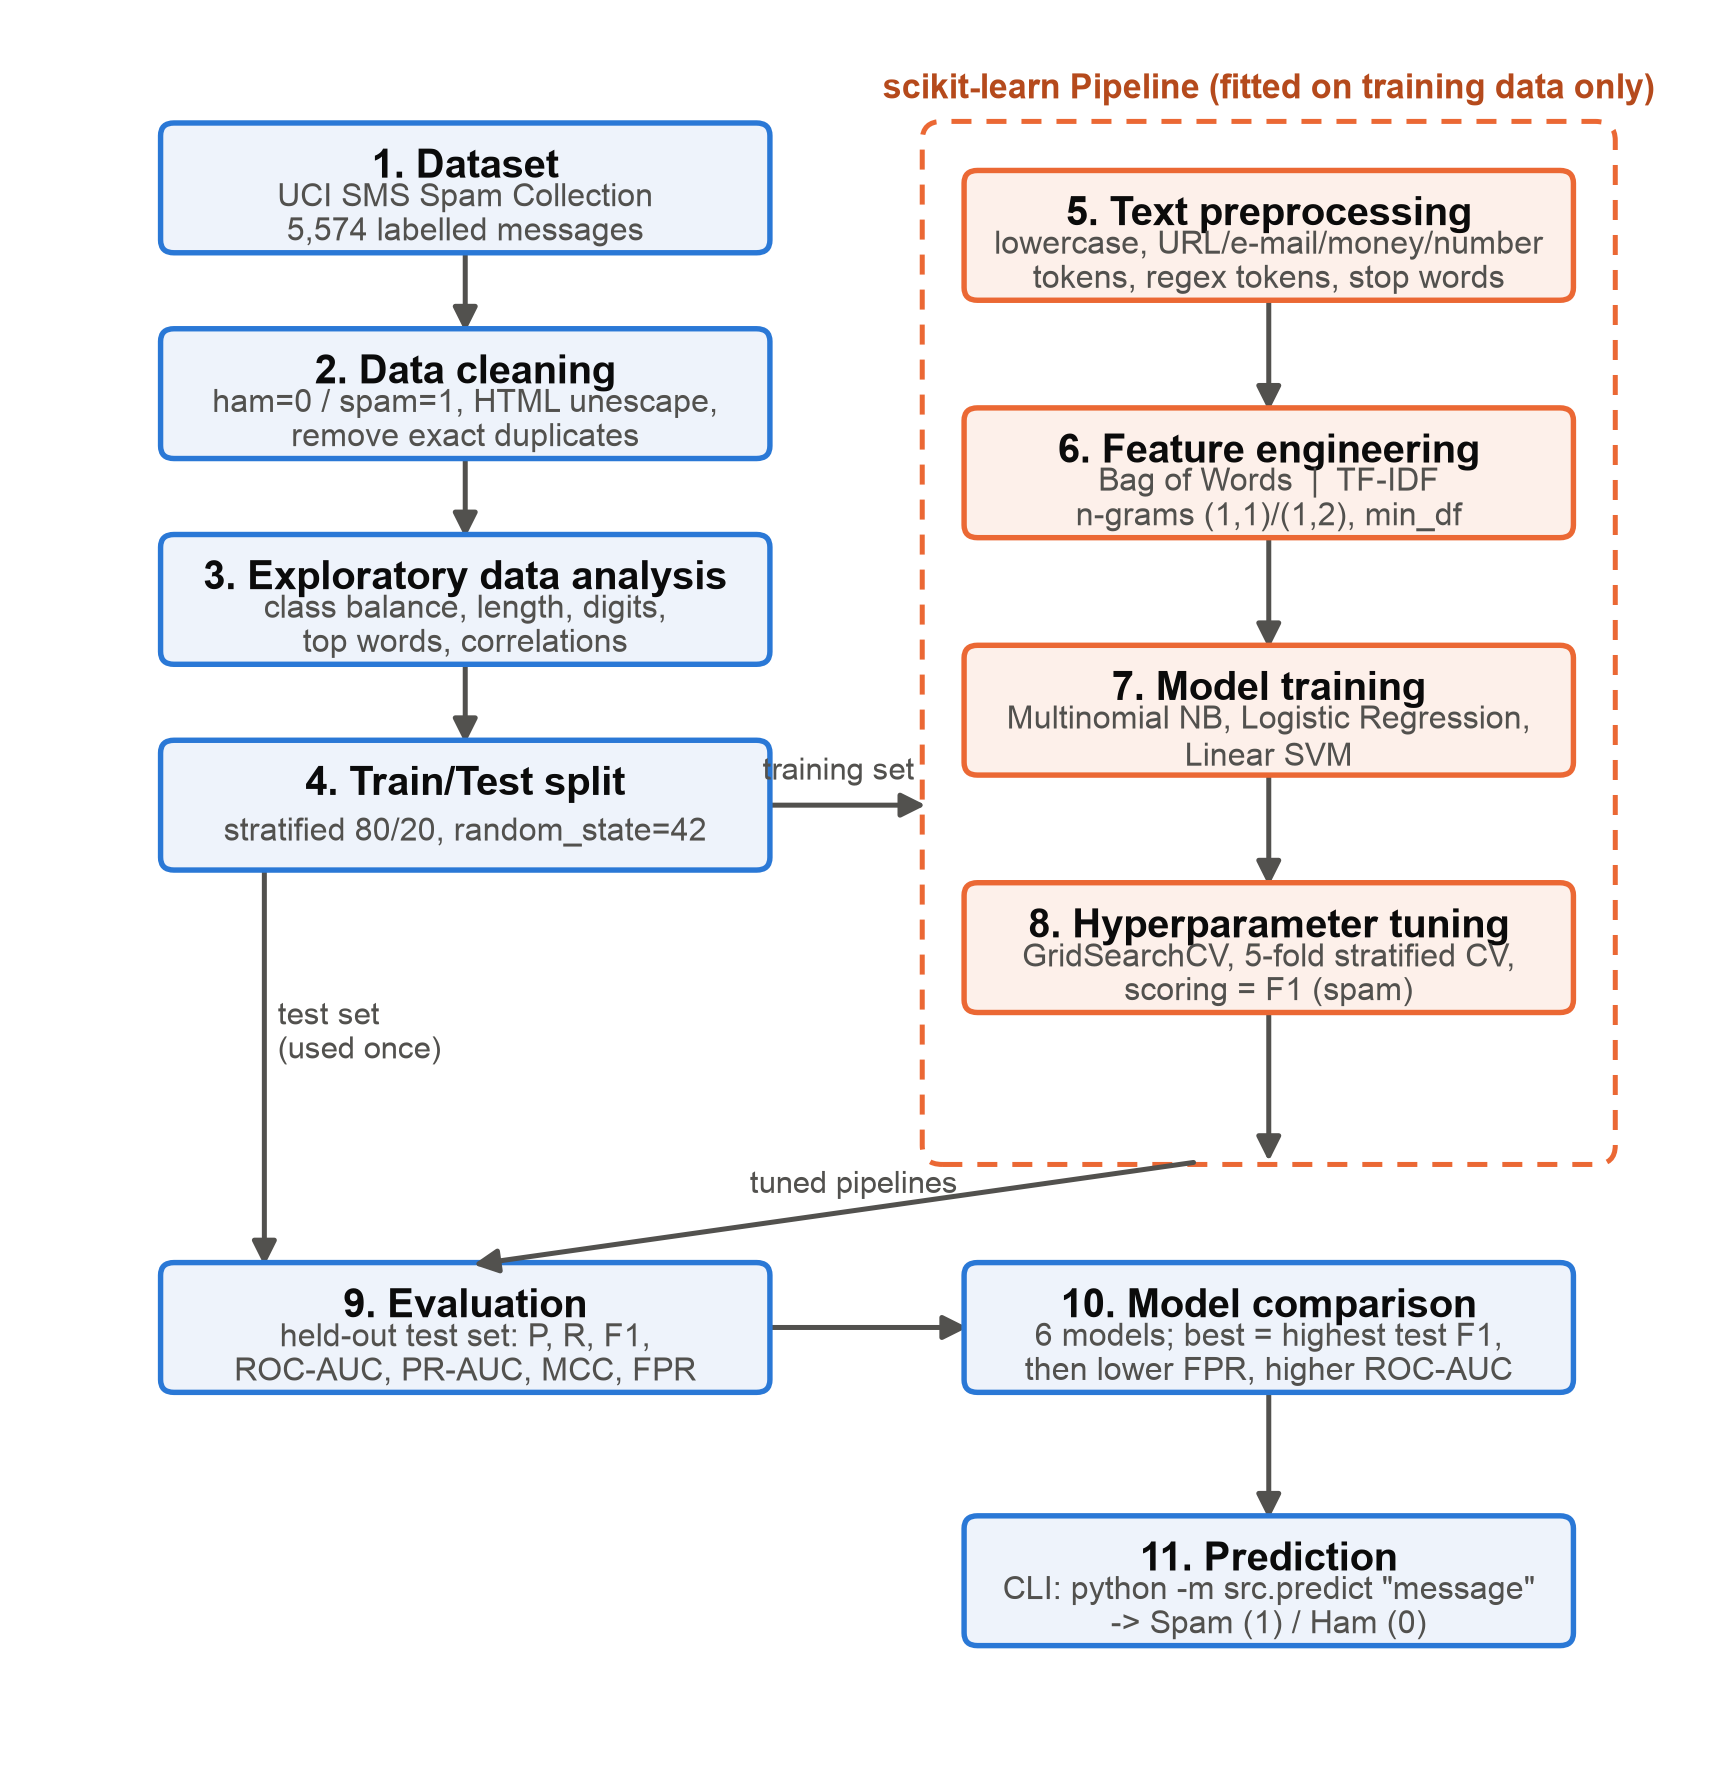

In [13]:
draw_workflow(); fig("fig_5_1_workflow.png", 600)

In [14]:
cv = train_all()
cv[["model", "best_params", "cv_f1_mean", "cv_f1_std", "refit_time_s", "vocab_size"]].round(4)

Training set: 4128 messages; test set: 1032 (test is not touched here)


  BoW_MultinomialNB            CV F1 = 0.9442 ± 0.0278 | {'clf__alpha': 1.0, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)} | 1.8s


  BoW_LogisticRegression       CV F1 = 0.9427 ± 0.0220 | {'clf__C': 100, 'clf__class_weight': 'balanced', 'vec__min_df': 2, 'vec__ngram_range': (1, 2)} | 1.2s


  BoW_LinearSVM                CV F1 = 0.9438 ± 0.0260 | {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'vec__min_df': 2, 'vec__ngram_range': (1, 2)} | 1.3s


  TF-IDF_MultinomialNB         CV F1 = 0.9489 ± 0.0184 | {'clf__alpha': 0.1, 'vec__min_df': 1, 'vec__ngram_range': (1, 2), 'vec__sublinear_tf': False} | 1.3s


  TF-IDF_LogisticRegression    CV F1 = 0.9491 ± 0.0210 | {'clf__C': 10, 'clf__class_weight': 'balanced', 'vec__min_df': 1, 'vec__ngram_range': (1, 1), 'vec__sublinear_tf': True} | 2.2s


  TF-IDF_LinearSVM             CV F1 = 0.9513 ± 0.0220 | {'clf__C': 1, 'clf__class_weight': 'balanced', 'vec__min_df': 1, 'vec__ngram_range': (1, 1), 'vec__sublinear_tf': True} | 2.2s


,model,best_params,cv_f1_mean,cv_f1_std,refit_time_s,vocab_size
0,BoW_MultinomialNB,"{""clf__alpha"": 1.0, ""vec__min_df"": 2, ""vec__ngram_range"": [1, 2]}",0.9442,0.0278,0.0817,5612
1,BoW_LogisticRegression,"{""clf__C"": 100, ""clf__class_weight"": ""balanced"", ""vec__min_df"": 2, ""vec__ngram_range"":...",0.9427,0.0220,0.0500,5612
2,BoW_LinearSVM,"{""clf__C"": 0.1, ""clf__class_weight"": ""balanced"", ""vec__min_df"": 2, ""vec__ngram_range"":...",0.9438,0.0260,0.0499,5612
3,TF-IDF_MultinomialNB,"{""clf__alpha"": 0.1, ""vec__min_df"": 1, ""vec__ngram_range"": [1, 2], ""vec__sublinear_tf"":...",0.9489,0.0184,0.0527,29447
4,TF-IDF_LogisticRegression,"{""clf__C"": 10, ""clf__class_weight"": ""balanced"", ""vec__min_df"": 1, ""vec__ngram_range"": ...",0.9491,0.0210,0.0389,6551
5,TF-IDF_LinearSVM,"{""clf__C"": 1, ""clf__class_weight"": ""balanced"", ""vec__min_df"": 1, ""vec__ngram_range"": [...",0.9513,0.0220,0.0414,6551


## 5. Results and evaluation (Report Chapter 6)
All six tuned pipelines are evaluated once on the same held-out test set. **Best-model rule:** highest test F1 (spam); ties broken by lower false positive rate, then higher ROC-AUC.

In [15]:
res = run_evaluation()
display(table("table_6_1_results.csv"))
print("Best model:", res["best_model_pretty"], "| McNemar (top 2):", res["mcnemar_top2"])

Figures:


  saved outputs/figures/fig_6_1_confusion_matrices.png
  saved outputs/figures/fig_6_2_roc_curves.png
  saved outputs/figures/fig_6_3_pr_curves.png


  saved outputs/figures/fig_6_4_metric_comparison.png
  saved outputs/figures/fig_6_5_bow_vs_tfidf.png
  saved outputs/figures/fig_6_6_cv_vs_test.png
  saved outputs/figures/fig_6_8_best_confusion_matrix.png
       Model  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC    FPR  FP  FN
    BoW + NB    0.9864     0.9453  0.9453 0.9453   0.9866  0.9686 0.0077   7   7
    BoW + LR    0.9922     0.9839  0.9531 0.9683   0.9972  0.9892 0.0022   2   6
   BoW + SVM    0.9903     0.9836  0.9375 0.9600   0.9978  0.9898 0.0022   2   8
 TF-IDF + NB    0.9864     0.9672  0.9219 0.9440   0.9942  0.9789 0.0044   4  10
 TF-IDF + LR    0.9913     0.9837  0.9453 0.9641   0.9981  0.9896 0.0022   2   7
TF-IDF + SVM    0.9913     0.9837  0.9453 0.9641   0.9979  0.9899 0.0022   2   7
Best model: BoW + LR; McNemar vs TF-IDF + LR: p = 1.0000


,Model,Vectorizer,Classifier,Accuracy,Precision,Recall,F1,Macro-F1,ROC-AUC,PR-AUC,MCC,FPR,FP,FN,Inference ms per 1000
0,BoW + NB,BoW,MultinomialNB,0.9864,0.9453,0.9453,0.9453,0.9688,0.9866,0.9686,0.9376,0.0077,7,7,9.0715
1,BoW + LR,BoW,LogisticRegression,0.9922,0.9839,0.9531,0.9683,0.9819,0.9972,0.9892,0.9640,0.0022,2,6,9.1031
2,BoW + SVM,BoW,LinearSVM,0.9903,0.9836,0.9375,0.9600,0.9772,0.9978,0.9898,0.9548,0.0022,2,8,9.0175
3,TF-IDF + NB,TF-IDF,MultinomialNB,0.9864,0.9672,0.9219,0.9440,0.9681,0.9942,0.9789,0.9366,0.0044,4,10,9.3352
4,TF-IDF + LR,TF-IDF,LogisticRegression,0.9913,0.9837,0.9453,0.9641,0.9796,0.9981,0.9896,0.9594,0.0022,2,7,7.7288
5,TF-IDF + SVM,TF-IDF,LinearSVM,0.9913,0.9837,0.9453,0.9641,0.9796,0.9979,0.9899,0.9594,0.0022,2,7,7.6082


Best model: BoW + LR | McNemar (top 2): {'a_correct_b_wrong': 6, 'a_wrong_b_correct': 5, 'n_discordant': 11, 'p_value_exact': 1.0, 'test': 'McNemar exact (binomial) test, two-sided', 'model_a': 'BoW_LogisticRegression', 'model_b': 'TF-IDF_LogisticRegression'}


In [16]:
display(table("table_6_2_cv_results.csv"))

,Model,CV F1 mean,CV F1 std,CV train F1,Test F1,Refit time (s),Grid search time (s),Candidates,Vocabulary
0,BoW + NB,0.9442,0.0278,0.9613,0.9453,0.0817,1.7892,20,5612
1,BoW + LR,0.9427,0.0220,1.0000,0.9683,0.0500,1.1723,32,5612
2,BoW + SVM,0.9438,0.0260,0.9976,0.9600,0.0499,1.2865,32,5612
3,TF-IDF + NB,0.9489,0.0184,1.0000,0.9440,0.0527,1.3269,40,29447
4,TF-IDF + LR,0.9491,0.0210,0.9959,0.9641,0.0389,2.1723,64,6551
5,TF-IDF + SVM,0.9513,0.0220,0.9966,0.9641,0.0414,2.2138,64,6551


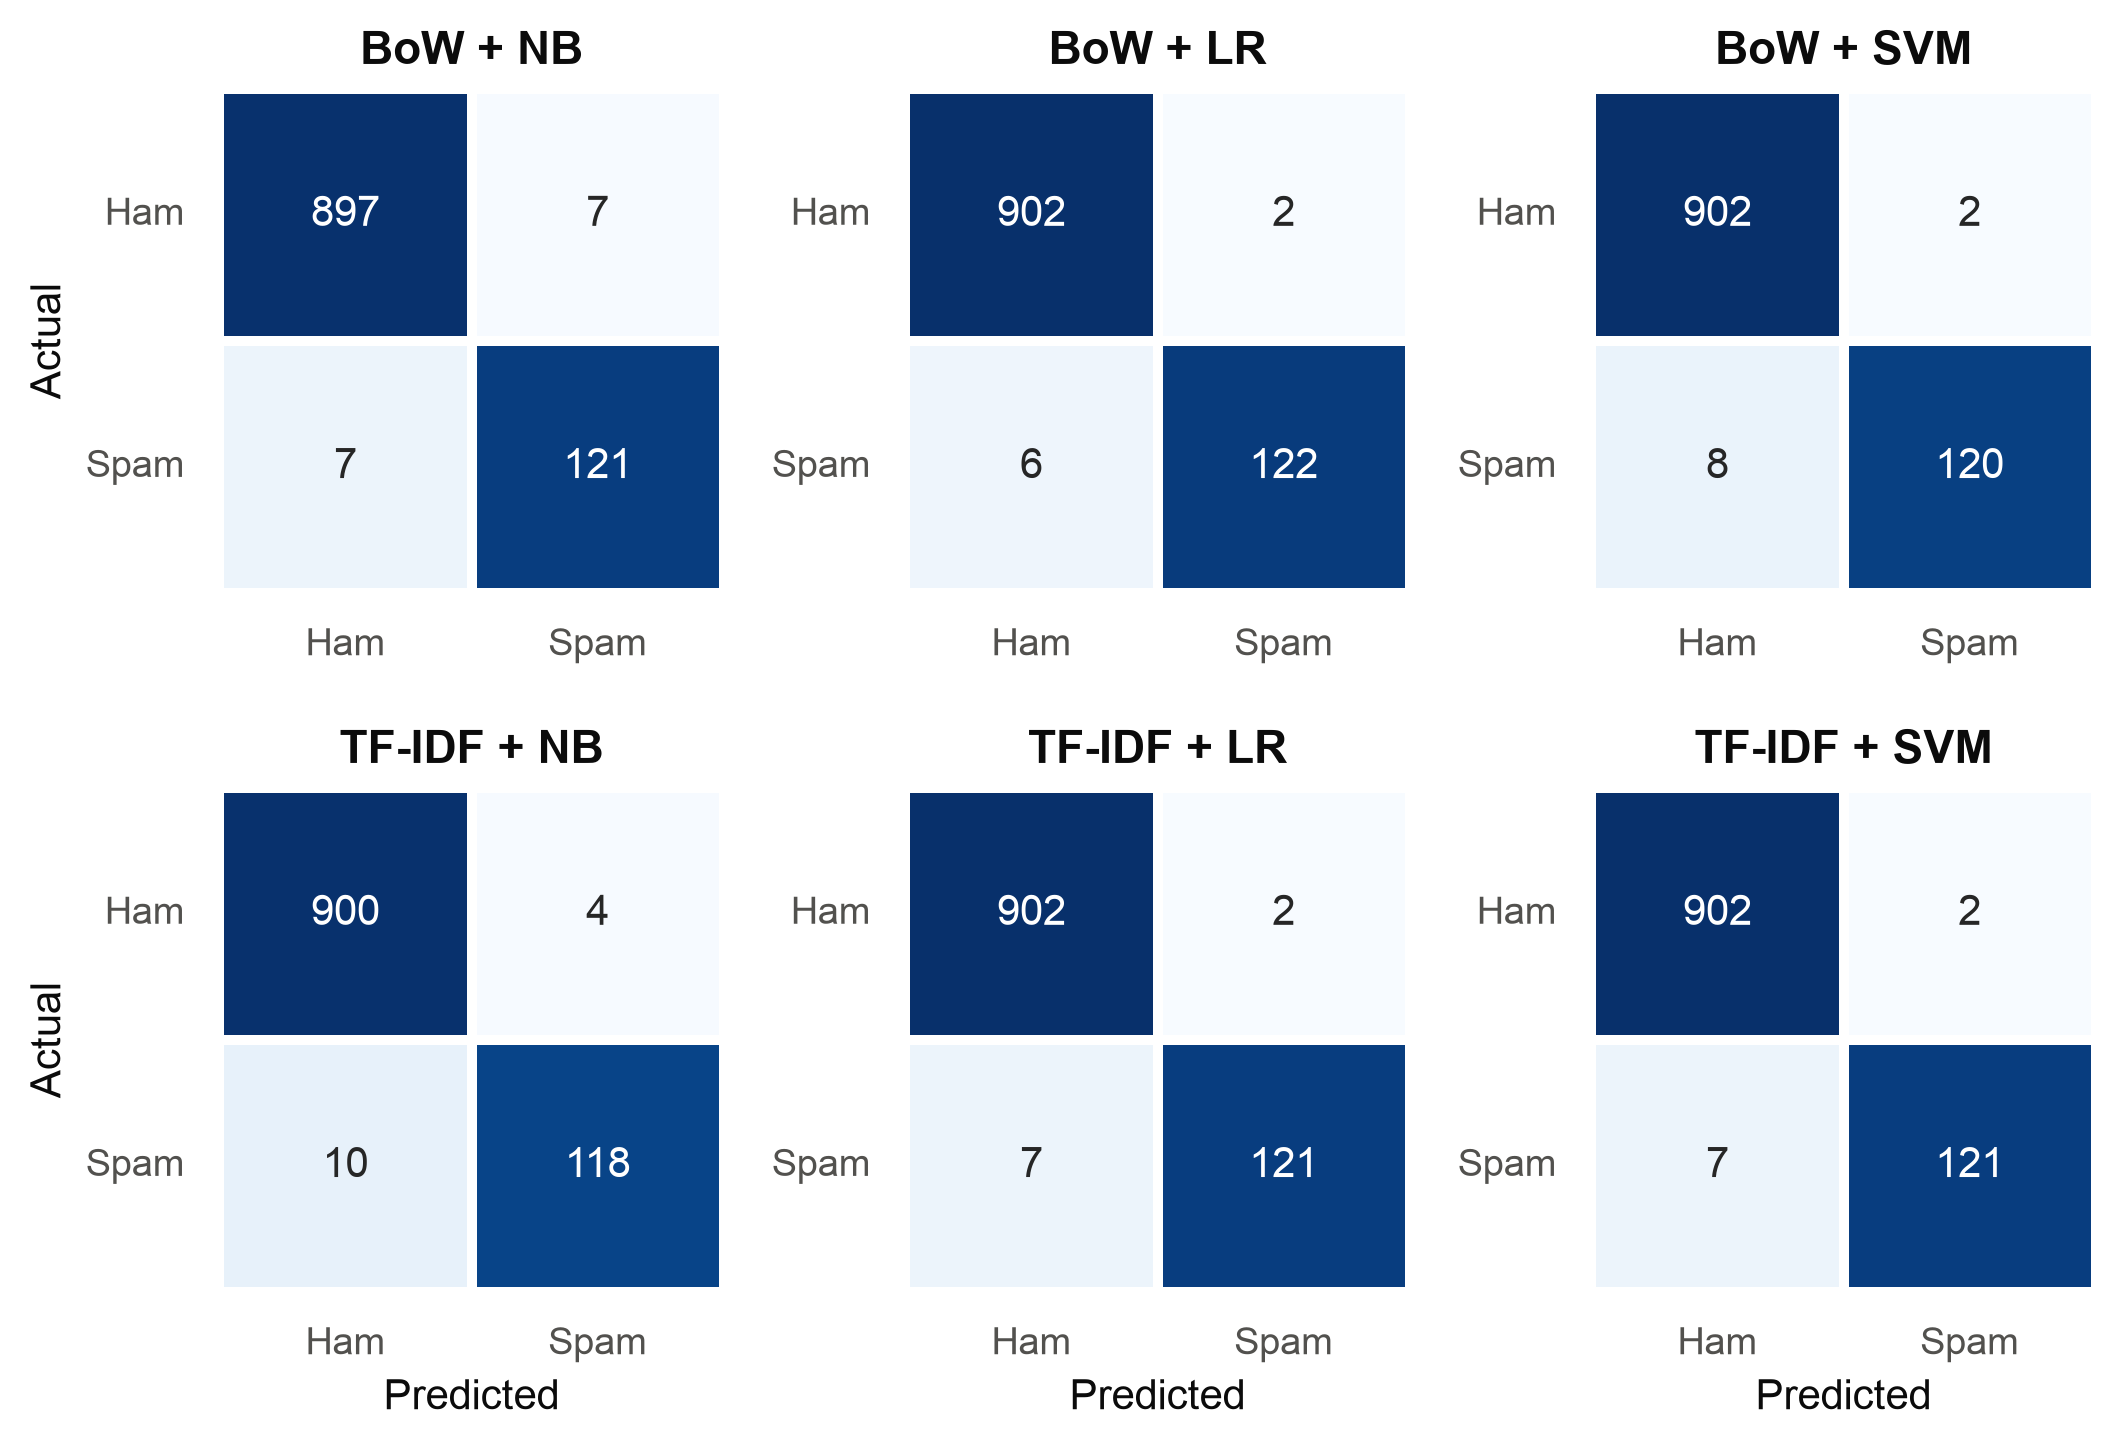

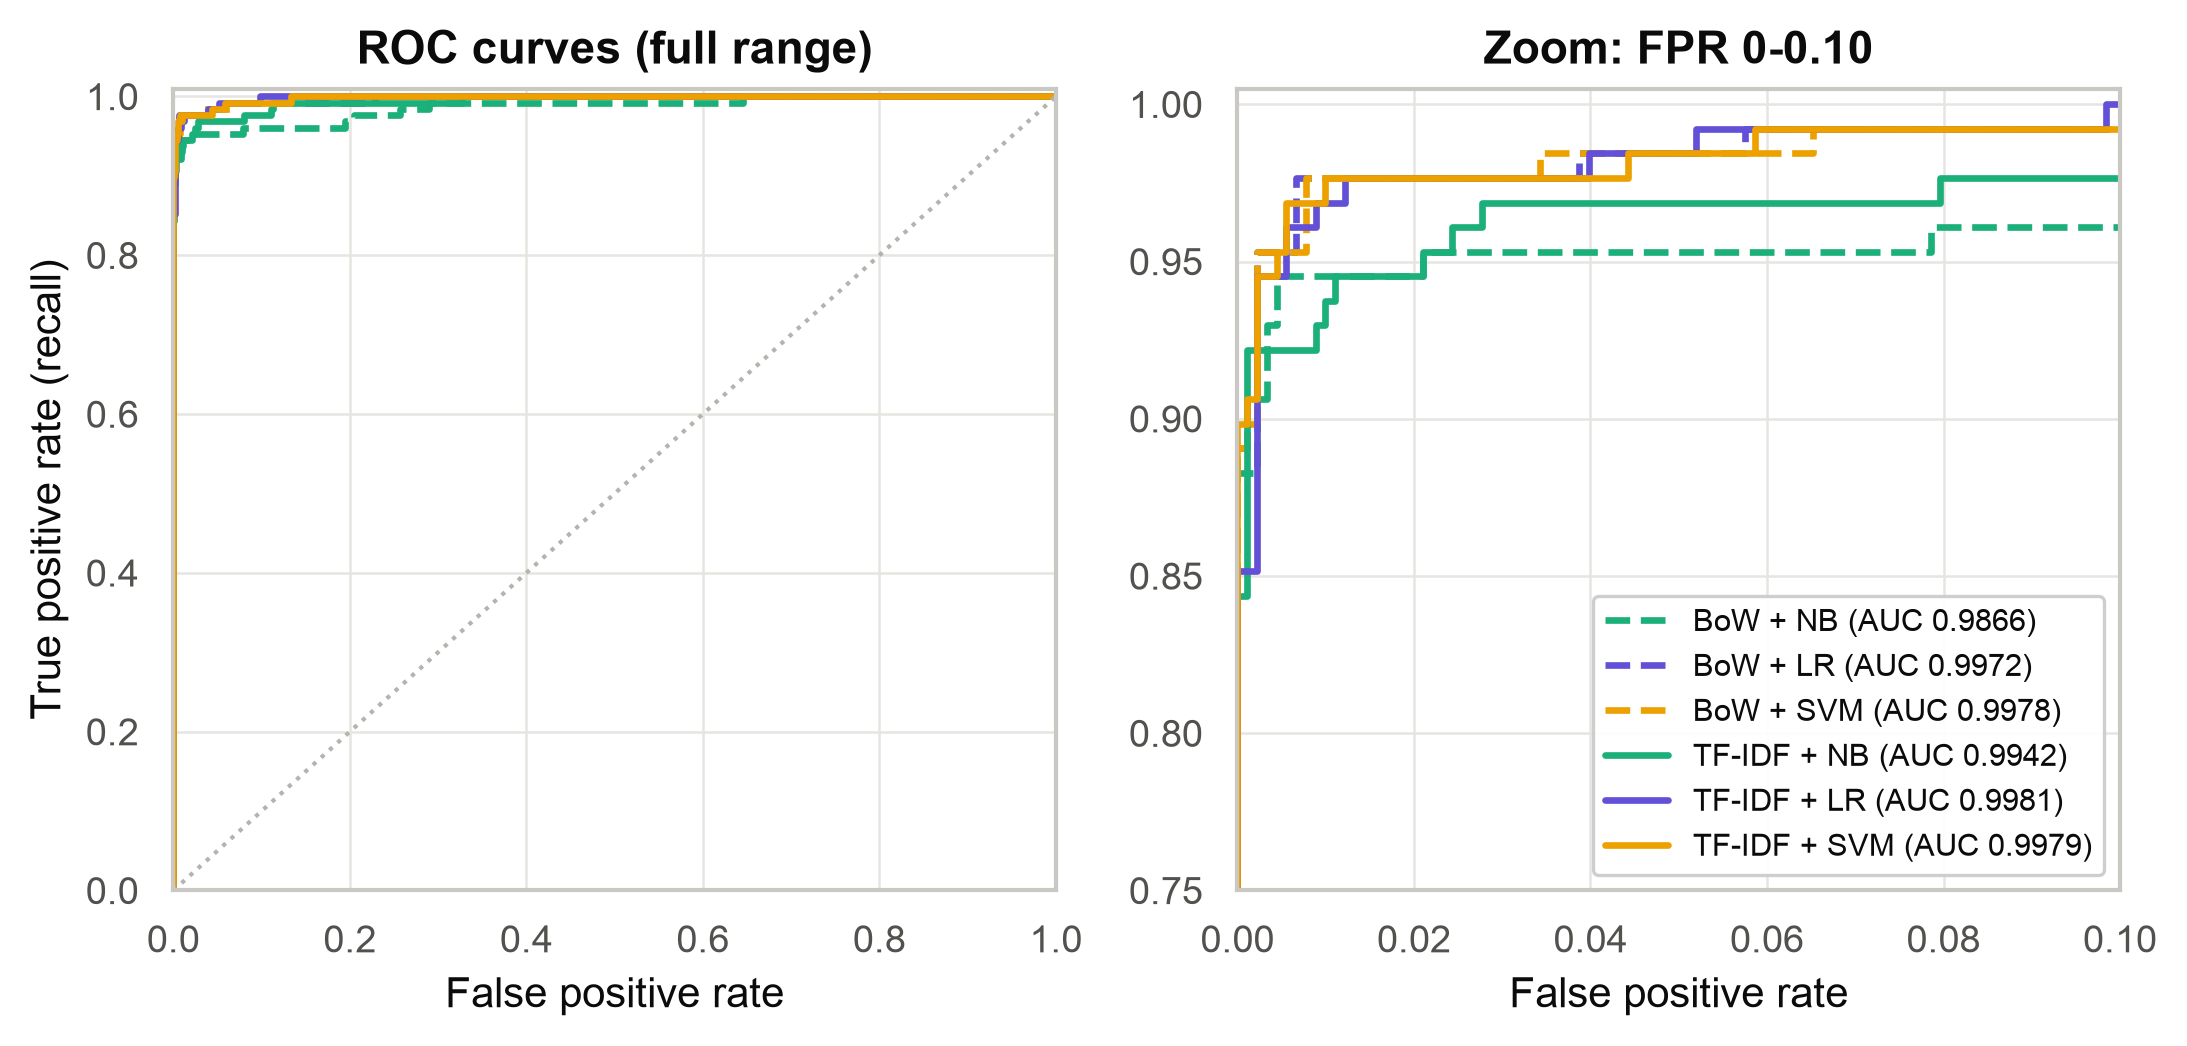

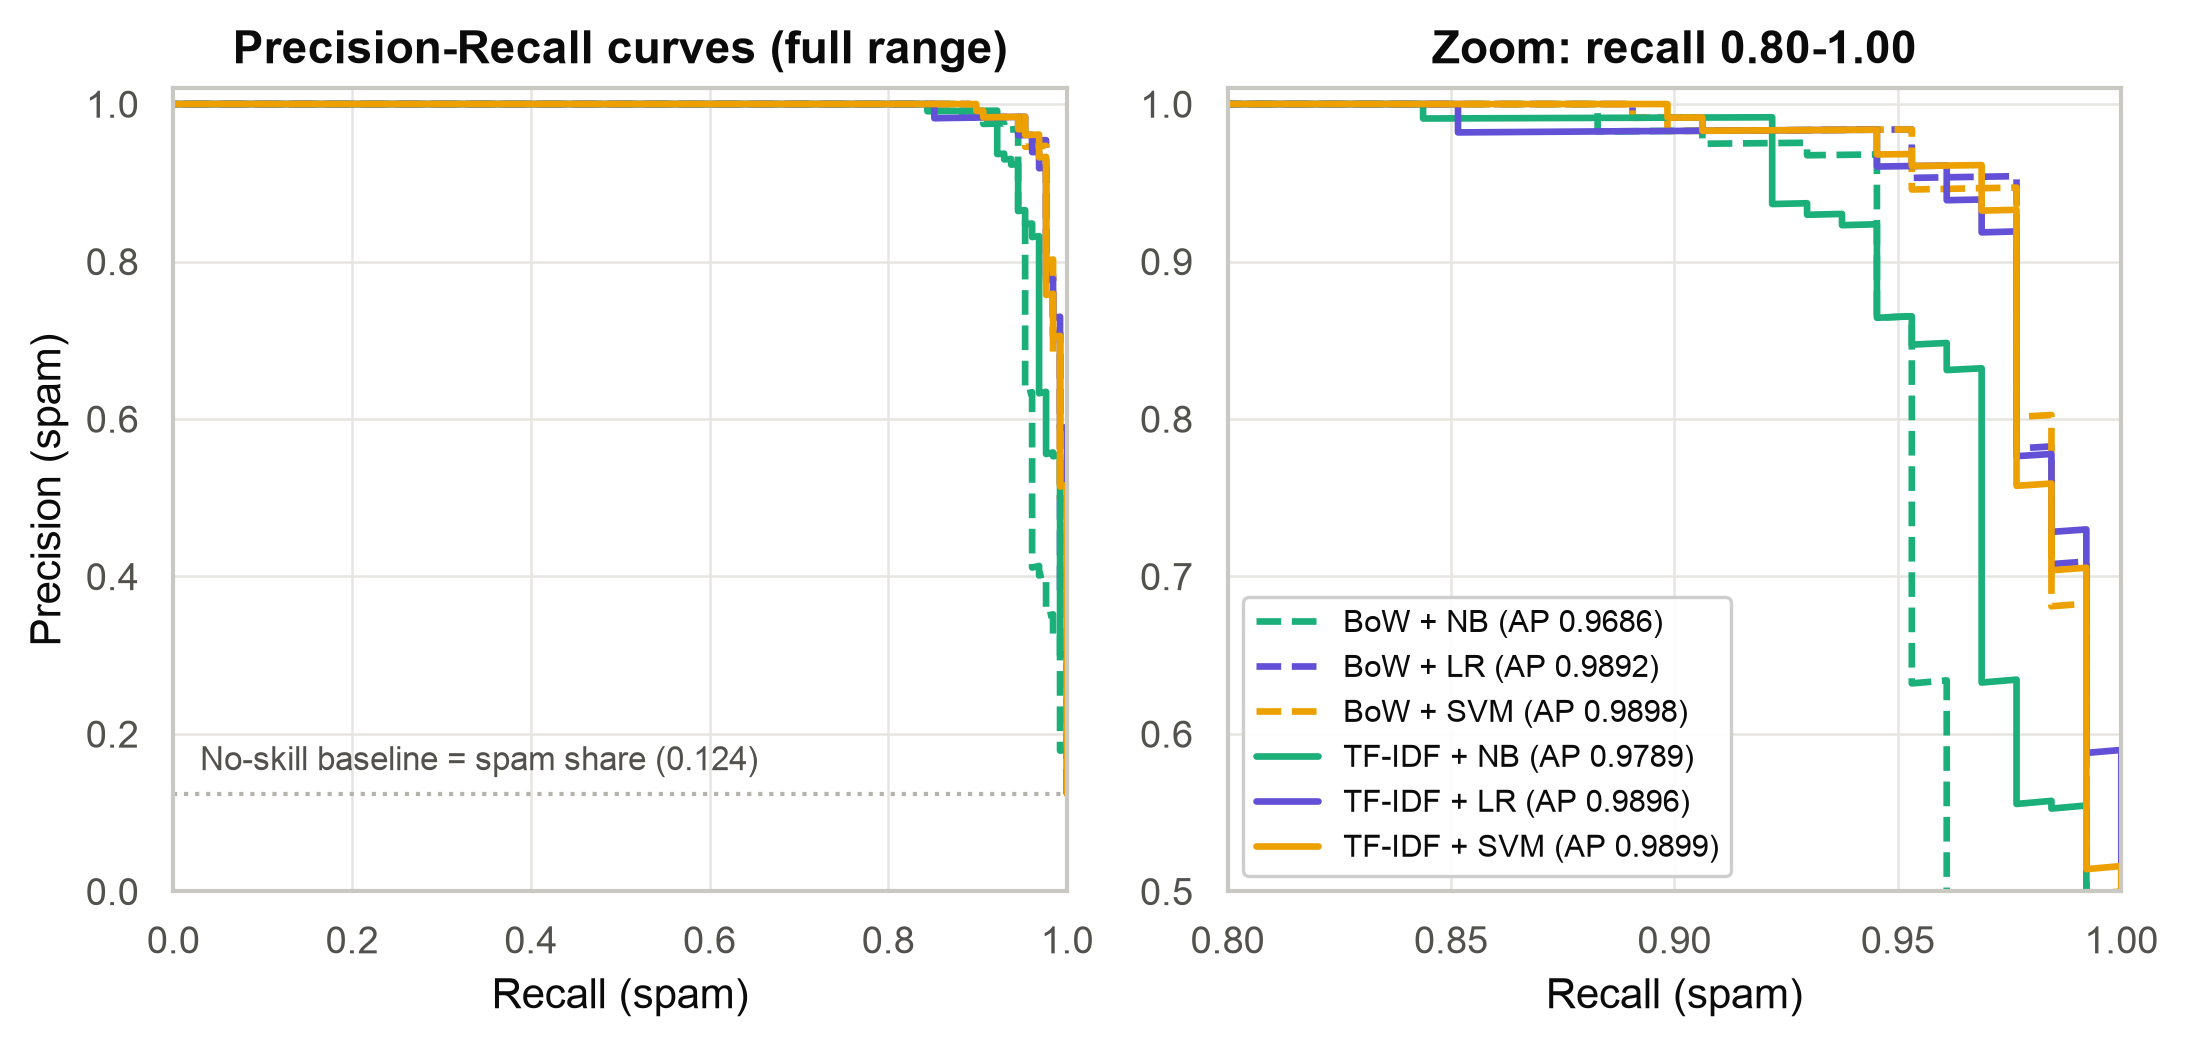

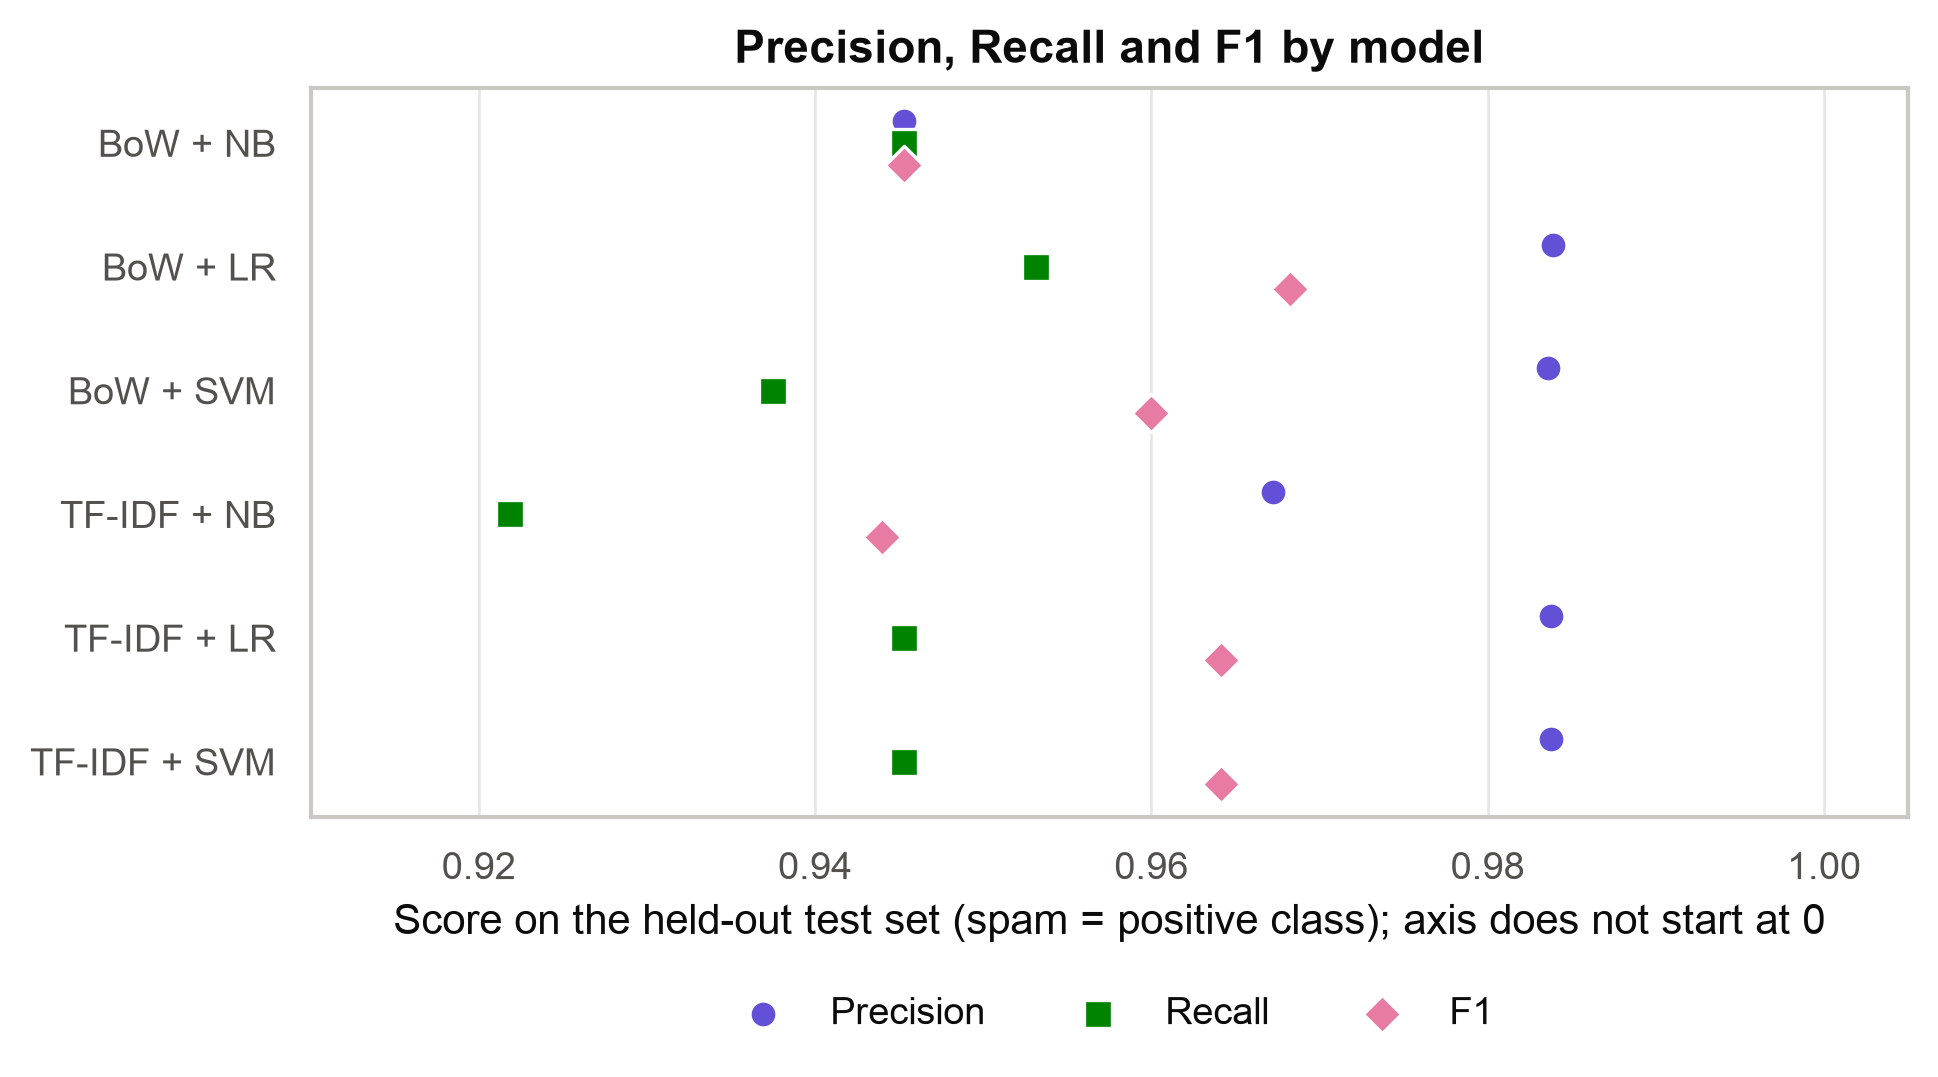

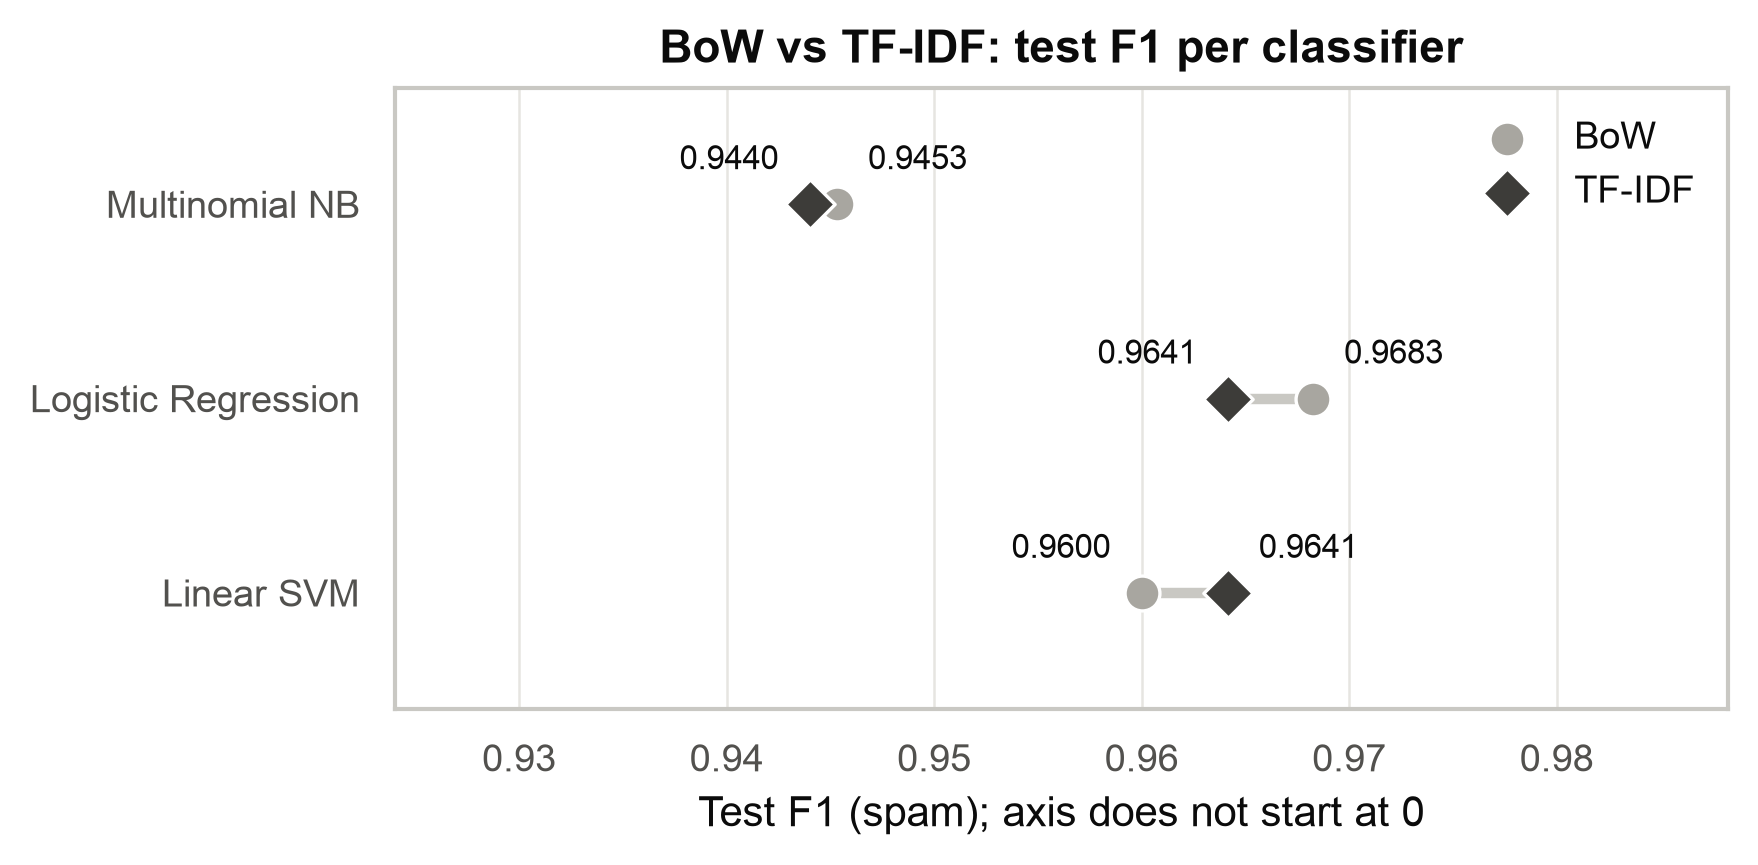

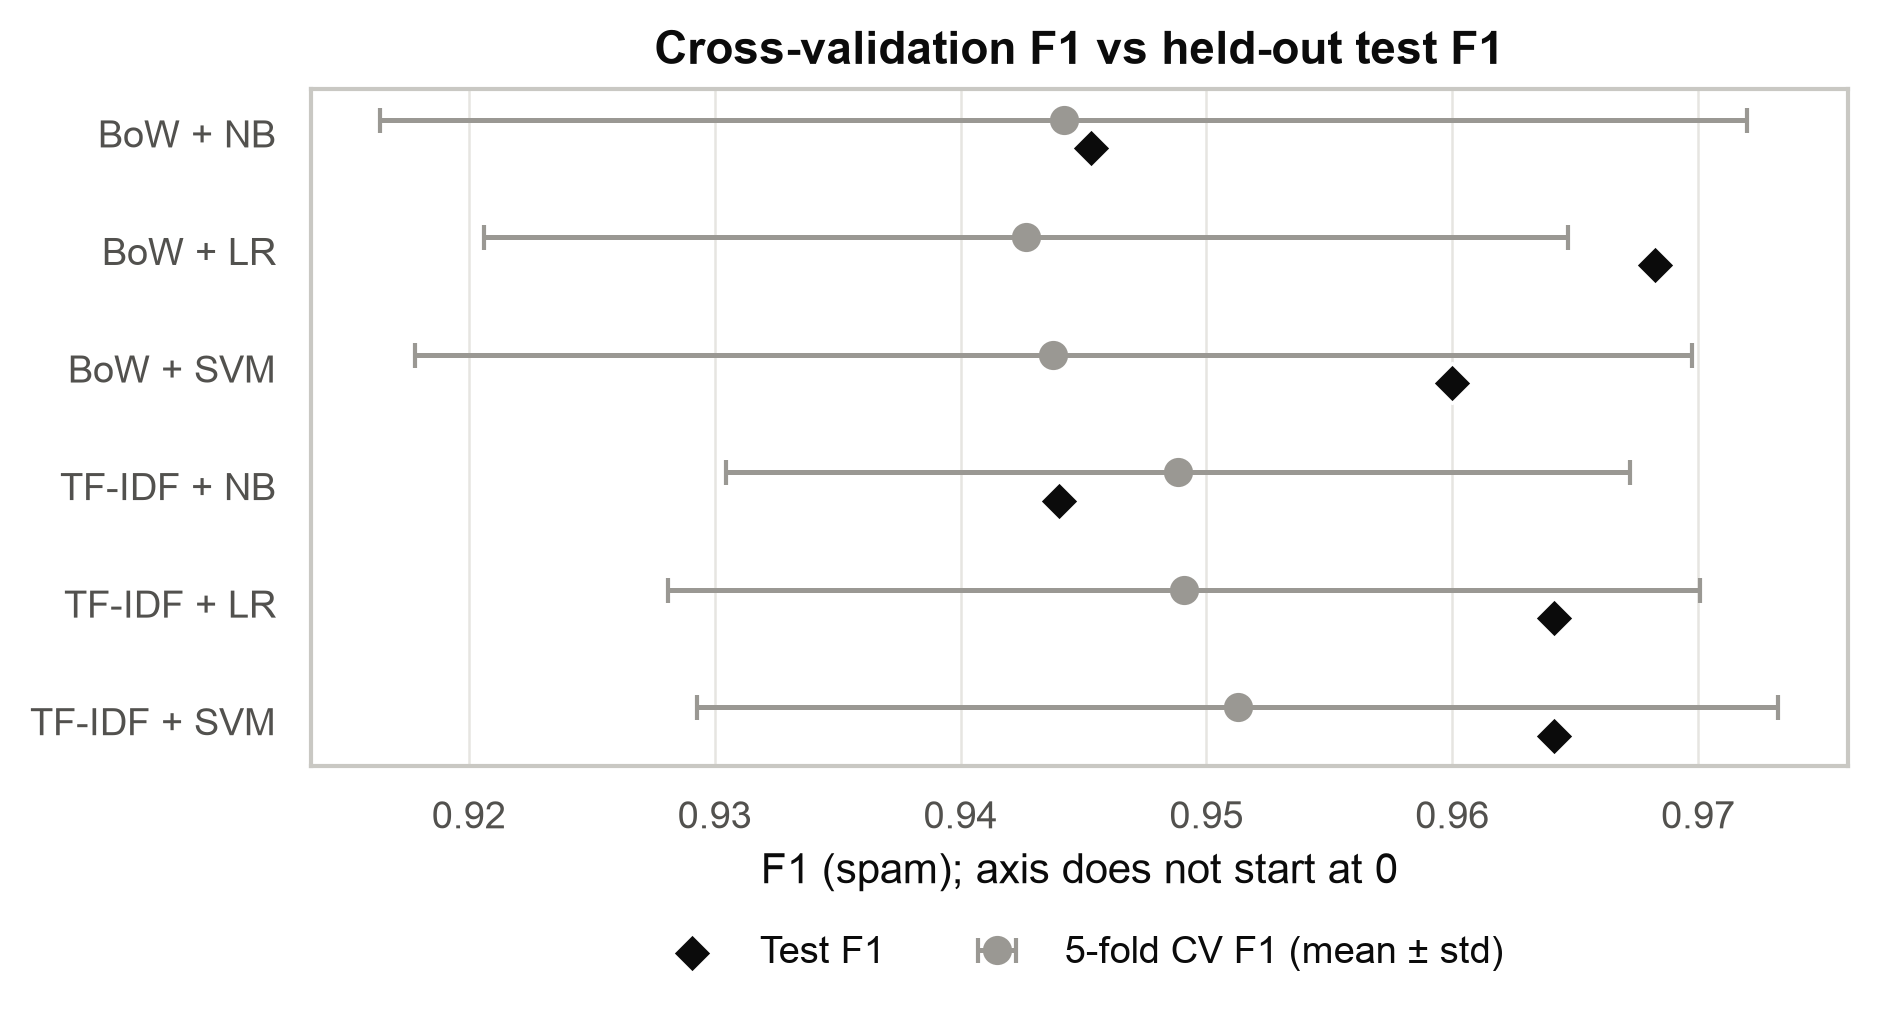

In [17]:
for f in ["fig_6_1_confusion_matrices.png", "fig_6_2_roc_curves.png", "fig_6_3_pr_curves.png",
          "fig_6_4_metric_comparison.png", "fig_6_5_bow_vs_tfidf.png", "fig_6_6_cv_vs_test.png"]:
    fig(f)

### 5.1 Interpretation (Fig. 6.7) and best-model confusion matrix (Fig. 6.8)

  saved outputs/figures/fig_6_7_top_features.png
Top spam tokens (best model): ['phonetoken', 'brought', 'rgds', 'urltoken', 'arsenal']


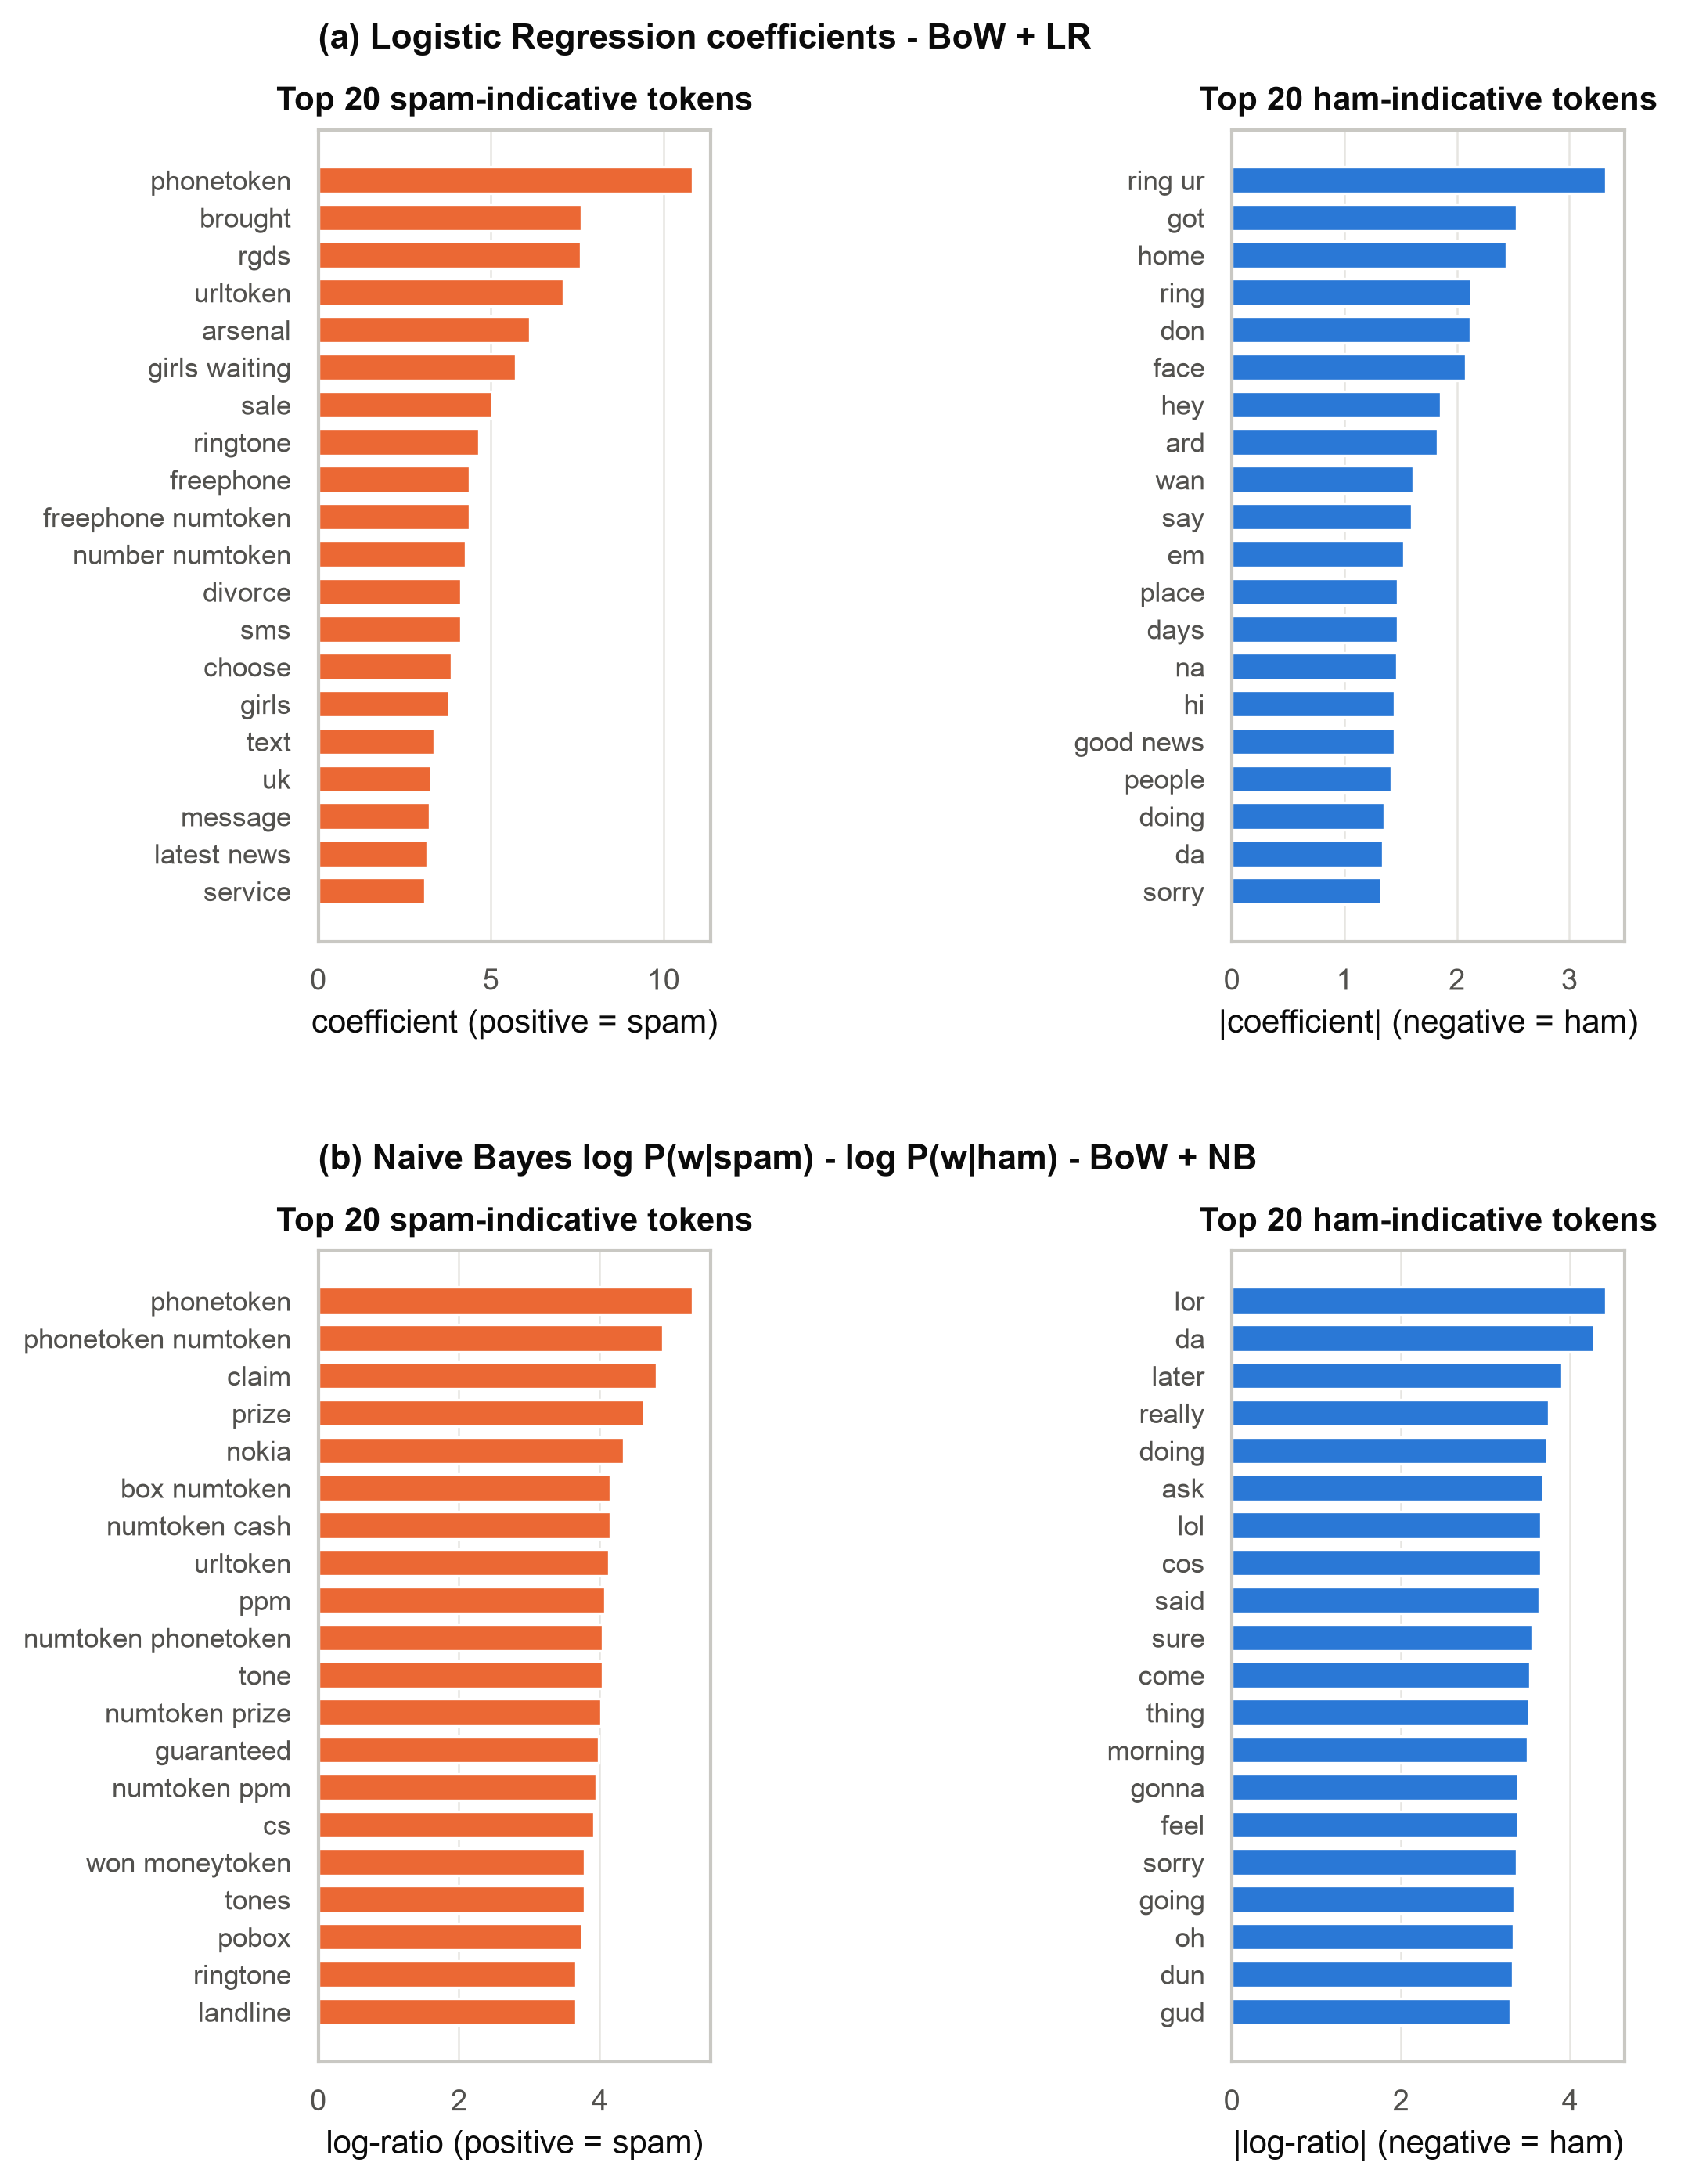

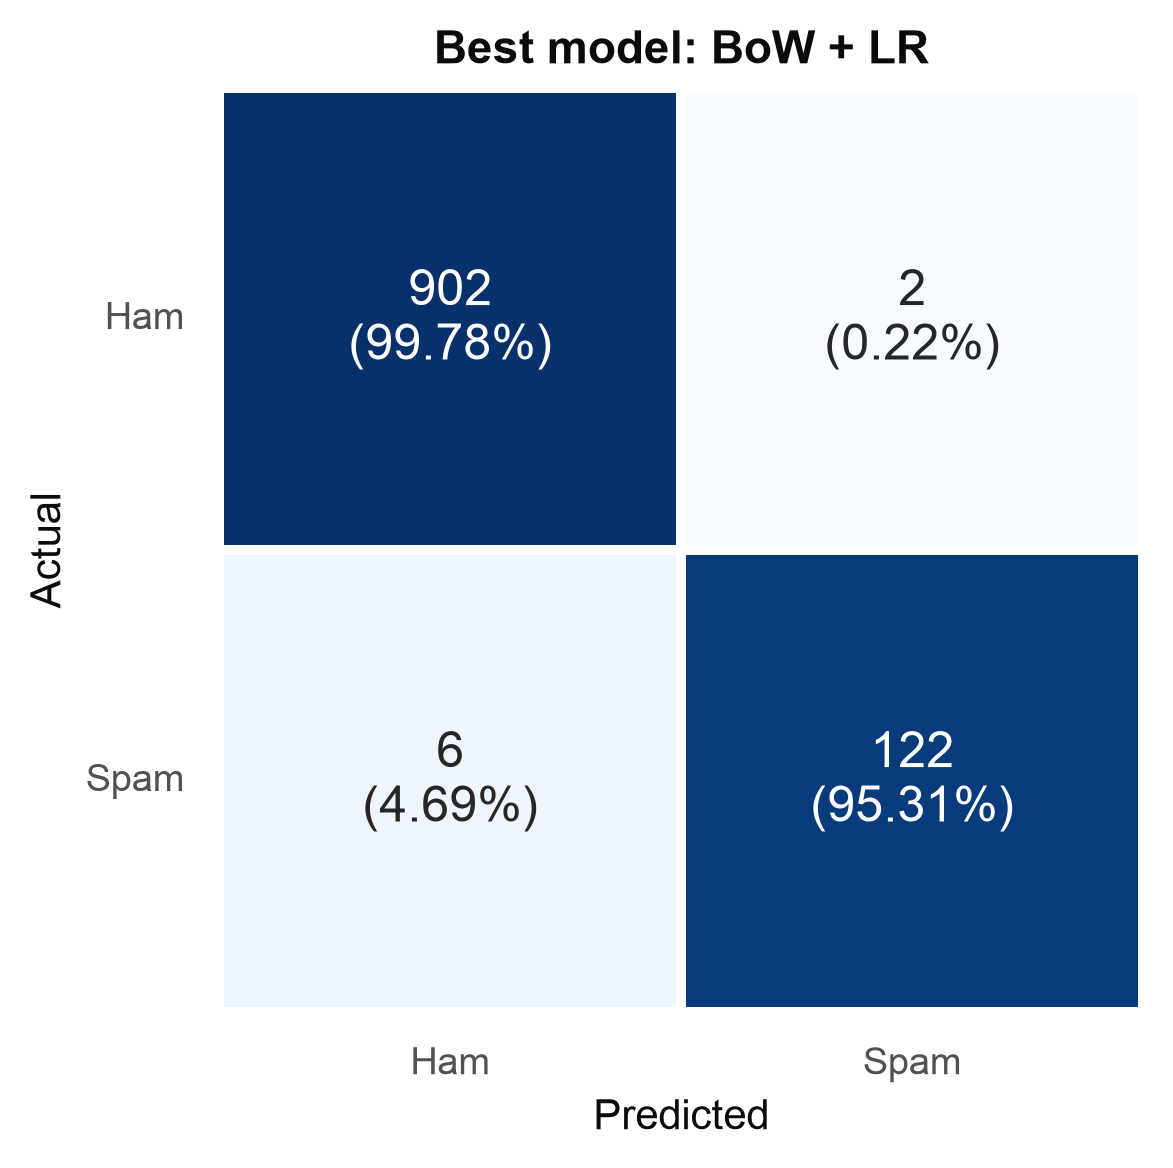

Top spam tokens of the best model: ['phonetoken', 'brought', 'rgds', 'urltoken', 'arsenal']


In [18]:
interp = run_interpretation()
fig("fig_6_7_top_features.png", 640); fig("fig_6_8_best_confusion_matrix.png", 420)
print("Top spam tokens of the best model:", interp["best_top_spam"][:5])

### 5.2 Error analysis (Table 6.3) and sample predictions (Tables 6.4, 6.5)

In [19]:
display(table("table_6_3_misclassified.csv"))
display(table("table_6_4_sample_predictions.csv"))

,error_type,text,actual,predicted,score
0,FN (spam missed),"Hi this is Amy, we will be sending you a free phone number in a couple of days, which ...",spam,ham,0.0006
1,FN (spam missed),dating:i have had two of these. Only started after i sent a text to talk sport radio l...,spam,ham,0.0036
2,FN (spam missed),thesmszone.com lets you send free anonymous and masked messages..im sending this messa...,spam,ham,0.0055
3,FN (spam missed),Welcome! Please reply with your AGE and GENDER to begin. e.g 24M,spam,ham,0.0608
4,FN (spam missed),Sorry! U can not unsubscribe yet. THE MOB offer package has a min term of 54 weeks> pl...,spam,ham,0.1120
5,FN (spam missed),Adult 18 Content Your video will be with you shortly,spam,ham,0.1777
6,FP (ham marked spam),Please protect yourself from e-threats. SIB never asks for sensitive information like ...,ham,spam,0.9159
7,FP (ham marked spam),I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove...,ham,spam,0.8336


,case,text,actual,predicted,score,correct
0,Typical ham,Double eviction this week - Spiral and Michael and good riddance to them!,ham,ham,0.0017,Yes
1,Typical ham,Thank You meet you monday,ham,ham,0.0004,Yes
2,Typical spam,"""For the most sparkling shopping breaks from 45 per person; call 0121 2025050 or visit...",spam,spam,1.0000,Yes
3,Typical spam,Free Msg: Ringtone!From: http://tms. widelive.com/index. wml?id=1b6a5ecef91ff9*37819&f...,spam,spam,1.0000,Yes
4,Hard case (closest to threshold),Adult 18 Content Your video will be with you shortly,spam,ham,0.1777,No


## 6. Appendix B — preprocessing ablation and learning curve

  (a) Full preprocessing (main pipeline)         CV 0.9427 ± 0.0220 | test 0.9683


  (b) No stop-word removal                       CV 0.9376 ± 0.0218 | test 0.9555


  (c) No number/URL/currency normalisation       CV 0.9135 ± 0.0289 | test 0.9512


  (d) Full preprocessing + Porter stemming       CV 0.9420 ± 0.0200 | test 0.9639
  (e) Raw text, lowercasing only                 CV 0.9131 ± 0.0210 | test 0.9274
  saved outputs/figures/fig_b_1_ablation.png


  saved outputs/figures/fig_b_2_learning_curve.png


,Variant,Description,CV F1 mean,CV F1 std,Test F1,Vocabulary
0,(a),Full preprocessing (main pipeline),0.9427,0.0220,0.9683,5612
1,(b),No stop-word removal,0.9376,0.0218,0.9555,9932
2,(c),No number/URL/currency normalisation,0.9135,0.0289,0.9512,5211
3,(d),Full preprocessing + Porter stemming,0.9420,0.0200,0.9639,5423
4,(e),"Raw text, lowercasing only",0.9131,0.0210,0.9274,10007


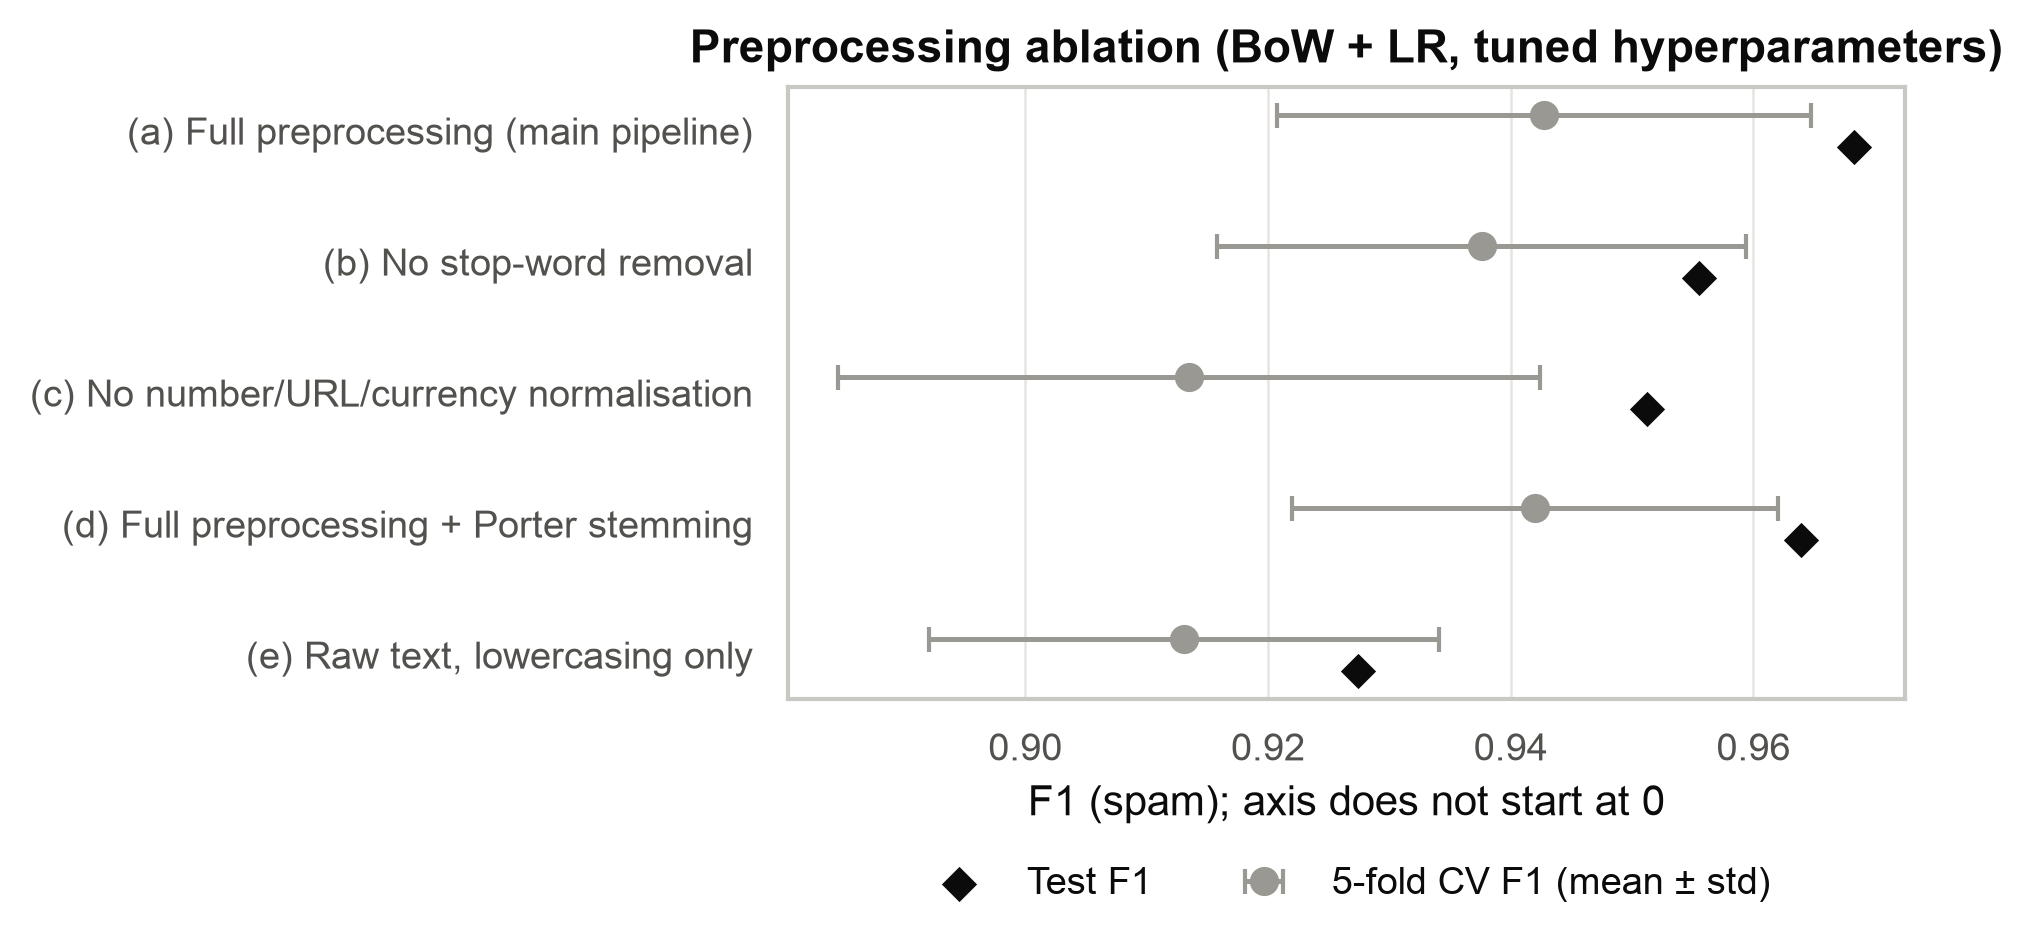

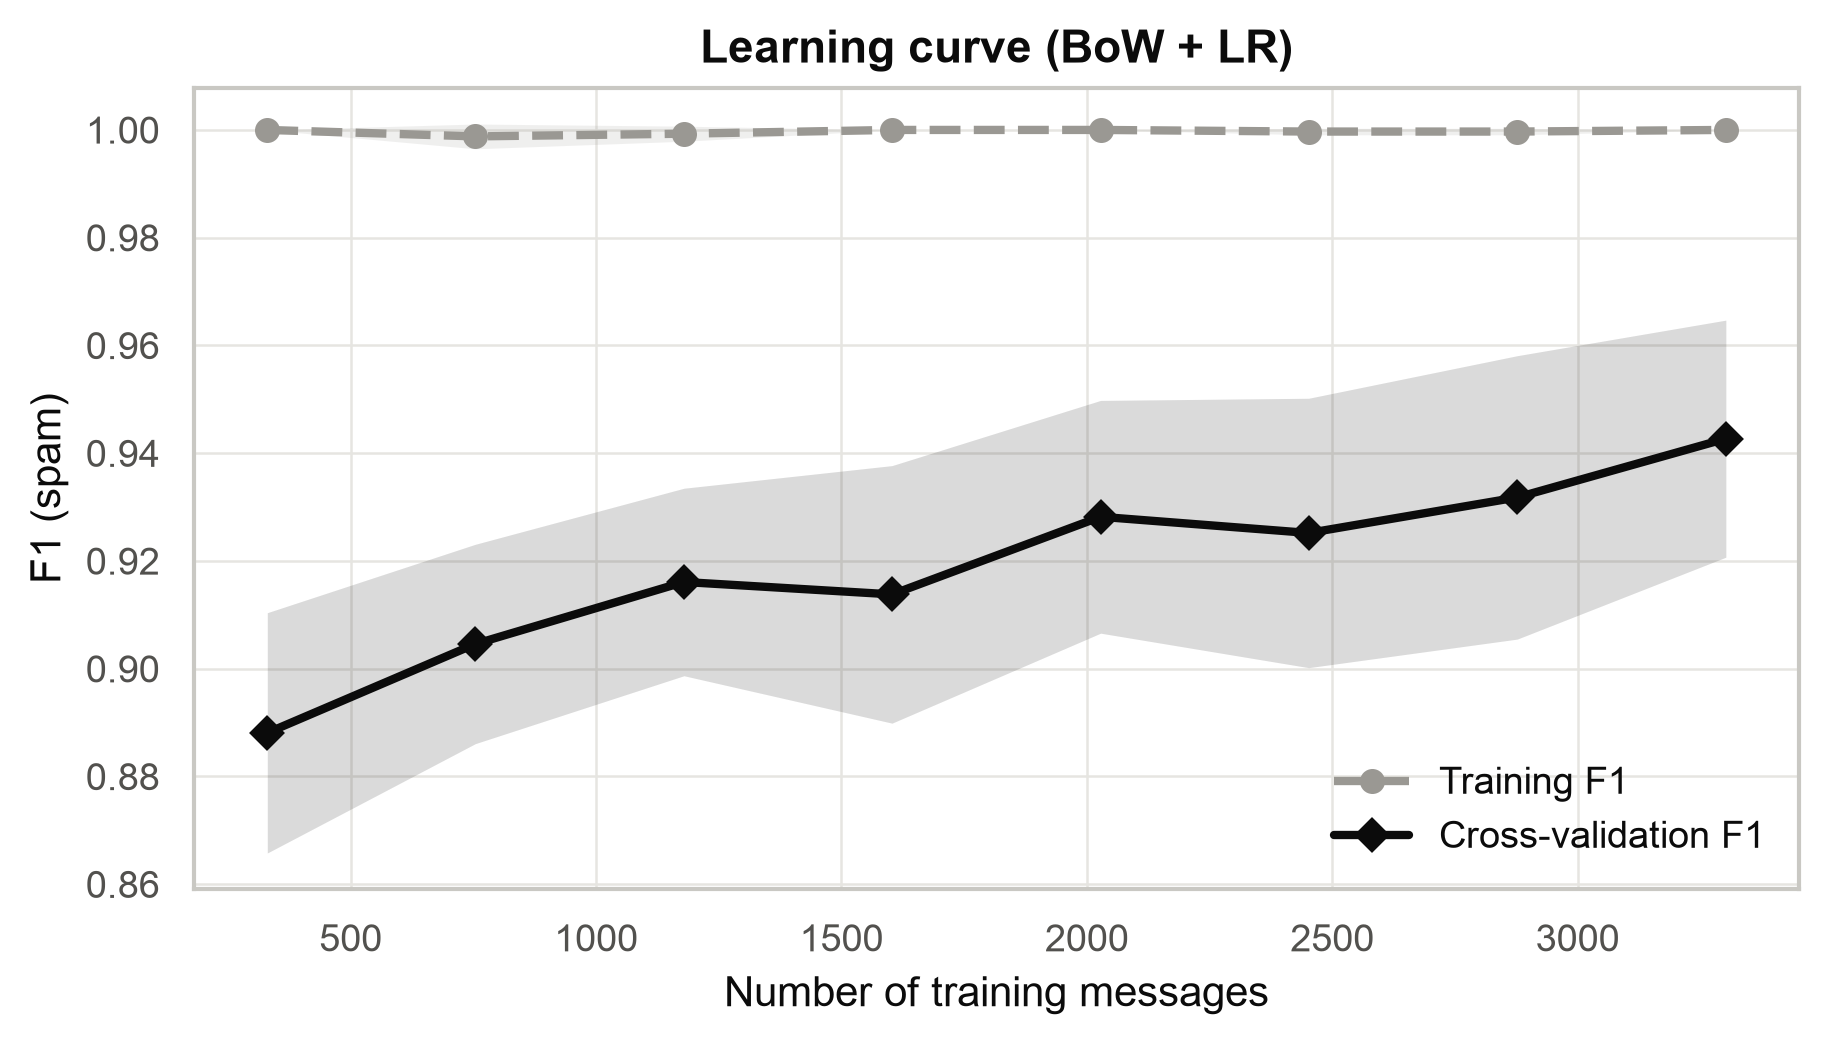

In [20]:
abl, lc = run_ablation()
display(abl)
fig("fig_b_1_ablation.png"); fig("fig_b_2_learning_curve.png")

## 7. Demo: predictions on new messages (not from the dataset)

In [21]:
from src.evaluate import CUSTOM_MESSAGES
results, meta = predict([t for t, _ in CUSTOM_MESSAGES])
print("Model:", meta["best_model_pretty"])
pd.DataFrame(results, columns=["message", "prediction", "score", "score type"]).round(4)

Model: BoW + LR


,message,prediction,score,score type
0,"Congratulations! You won a £1000 voucher, call 09061234567 now to claim",Spam (1),1.0000,P(spam)
1,"Hey, are we still meeting at 5?",Ham (0),0.0002,P(spam)
2,Your OTP for login is 482913. Do not share it with anyone.,Spam (1),0.9704,P(spam)
3,Your parcel is out for delivery today. Track it at www.example-courier.com/track,Spam (1),0.5995,P(spam)
4,"I got a free ticket for the match tonight, want to come with me?",Ham (0),0.0001,P(spam)
